## 1. IMPORT DATA

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
os.listdir('/content/drive/MyDrive/Skripsi-InkSkyCat')

['logs-prod-2026-11-19.csv',
 'per_student_full',
 'PREPOST_student_per_KC.csv',
 'PREPOST_overall_results.csv',
 'PREPOST_student_overall.csv',
 'PREPOST_KC_results.csv',
 'ANALYSIS_student_scores.csv',
 'ANALYSIS_kc_summary.csv',
 'CLEAN_duplicates_removed.csv',
 'CLEAN_pretest.csv',
 'CLEAN_practice.csv',
 'CLEAN_posttest.csv',
 'CLEAN_all.csv']

In [3]:
import pandas as pd

# Path to the CSV file in Google Drive
csv_path = '/content/drive/MyDrive/Skripsi-InkSkyCat/logs-prod-2026-11-19.csv'

df = pd.read_csv(csv_path)

print(df.shape)       # Number of rows and columns
print(df.columns.tolist())  # Column names
df.head()             # Preview the first 5 rows

(9803, 16)
['_id', 'sessionId', 'userId', 'sessionType', 'chapterId', 'nodeId', 'questionId', 'questionStepId', 'kcId', 'selectedOption', 'isCorrect', 'pLBefore', 'pLAfter', 'responseTimeMs', 'timestamp._seconds', 'timestamp._nanoseconds']


,_id,sessionId,userId,sessionType,chapterId,nodeId,questionId,questionStepId,kcId,selectedOption,isCorrect,pLBefore,pLAfter,responseTimeMs,timestamp._seconds,timestamp._nanoseconds
0,001d2fce-6fa1-4c67-b455-997c92a52461_ch3_train...,001d2fce-6fa1-4c67-b455-997c92a52461,USER727,practice,chapter_3,ch3_training_3,Q-511,Q-511_cycle_1_step_1,KC-05,2x + (x - 3) = 15,True,0.99,0.990000,37011,1795064048,198000000
1,001d2fce-6fa1-4c67-b455-997c92a52461_ch3_train...,001d2fce-6fa1-4c67-b455-997c92a52461,USER727,practice,chapter_3,ch3_training_3,Q-511,Q-511_cycle_1_step_2,KC-03,3x - 3 = 15,True,0.99,0.990000,13822,1795064063,64000000
2,001d2fce-6fa1-4c67-b455-997c92a52461_ch3_train...,001d2fce-6fa1-4c67-b455-997c92a52461,USER727,practice,chapter_3,ch3_training_3,Q-511,Q-511_cycle_1_step_3,KC-01,6x = 15,False,0.99,0.943868,5379,1795064070,357000000
3,001d2fce-6fa1-4c67-b455-997c92a52461_ch3_train...,001d2fce-6fa1-4c67-b455-997c92a52461,USER727,practice,chapter_3,ch3_training_3,Q-511,Q-511_cycle_1_step_4,KC-02,x = 6,True,0.99,0.990000,3398,1795064075,705000000
4,001d2fce-6fa1-4c67-b455-997c92a52461_ch3_train...,001d2fce-6fa1-4c67-b455-997c92a52461,USER727,practice,chapter_3,ch3_training_3,Q-517,Q-517_cycle_1_step_1,KC-05,3y - 5 + y = 27,True,0.99,0.990000,29671,1795064106,398000000


## 2. EXPLORATORY DATA ANALYSIS

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (13, 5)
plt.rcParams['axes.titlesize'] = 12

# Load & backup
csv_path = '/content/drive/MyDrive/Skripsi-InkSkyCat/logs-prod-2026-11-19.csv'
df = pd.read_csv(csv_path)
df_orig = df.copy()
df['isCorrect'] = df['isCorrect'].astype(bool)

In [84]:
print("="*60)
print(f"Total rows           : {len(df):,}")
print(f"Total unique users   : {df['userId'].nunique():,}")
print(f"Total unique sessions: {df['sessionId'].nunique():,}")
print(f"Session types        : {df['sessionType'].value_counts().to_dict()}")
print(f"Duplicate _id        : {df['_id'].duplicated().sum()}")
print(f"Total missing values : {df.isna().sum().sum()}")
print("="*60)

# Missing values per column
print("\nMissing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])

# Descriptive statistics for response time
print("\nResponse Time (ms) — descriptive:")
print(df['responseTimeMs'].describe(percentiles=[.01,.05,.1,.25,.5,.75,.9,.95,.99]).round(0))

# Overall accuracy
print(f"\nOverall accuracy    : {df['isCorrect'].mean()*100:.2f}%")

Total rows           : 9,803
Total unique users   : 64
Total unique sessions: 1,154
Session types        : {'practice': 5927, 'pretest': 1985, 'posttest': 1891}
Duplicate _id        : 0
Total missing values : 0

Missing values per column:
Series([], dtype: int64)

Response Time (ms) — descriptive:
count      9803.0
mean      17196.0
std       22137.0
min         124.0
1%          486.0
5%         1607.0
10%        2833.0
25%        5386.0
50%       10315.0
75%       20376.0
90%       38169.0
95%       55795.0
99%      107008.0
max      496216.0
Name: responseTimeMs, dtype: float64

Overall accuracy    : 73.04%


In [124]:
# Thresholds — can be adjusted
FAST_1S    = 1000    # < 1s  : nearly impossible to read the question
FAST_3S    = 3000    # < 3s  : very fast response, possibly guessing
FAST_WRONG = 5000    # wrong & < 5s : strong indicator of guessing

df['is_too_fast']    = df['responseTimeMs'] < FAST_1S
df['is_fast']        = df['responseTimeMs'] < FAST_3S
df['is_fast_wrong']  = (df['responseTimeMs'] < FAST_WRONG) & (~df['isCorrect'])
df['is_invalid']     = df['responseTimeMs'].isna() | (df['responseTimeMs'] <= 0)

print("="*55)
print(f"Invalid (NaN / ≤0 ms)      : {df['is_invalid'].sum():>5}  ({df['is_invalid'].mean()*100:.2f}%)")
print(f"Too fast (<1s)              : {df['is_too_fast'].sum():>5}  ({df['is_too_fast'].mean()*100:.2f}%)")
print(f"Fast (<3s)                  : {df['is_fast'].sum():>5}  ({df['is_fast'].mean()*100:.2f}%)")
print(f"Fast + incorrect (<5s)      : {df['is_fast_wrong'].sum():>5}  ({df['is_fast_wrong'].mean()*100:.2f}%)")
print("="*55)

Invalid (NaN / ≤0 ms)      :     0  (0.00%)
Too fast (<1s)              :   343  (3.50%)
Fast (<3s)                  :  1071  (10.93%)
Fast + incorrect (<5s)      :   609  (6.21%)


In [125]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (13, 5)

csv_path = '/content/drive/MyDrive/Skripsi-InkSkyCat/logs-prod-2026-11-19.csv'
df_raw = pd.read_csv(csv_path).copy()          # ← RAW, jangan disentuh
df_raw['isCorrect'] = df_raw['isCorrect'].astype(bool)

print(f"Raw dataset : {len(df_raw):,} baris | {df_raw['userId'].nunique()} user | "
      f"{df_raw['sessionId'].nunique()} session")
print(df_raw['sessionType'].value_counts())

Raw dataset : 9,803 baris | 64 user | 1154 session
sessionType
practice    5927
pretest     1985
posttest    1891
Name: count, dtype: int64


Duplicate _id              : 0
Missing userId             : 0
Missing responseTimeMs     : 0
RT ≤ 0                     : 0

Response Time per Session Type:
  practice   | n= 5927 | P10=   3221ms | median=  10474ms | P90=   38626ms


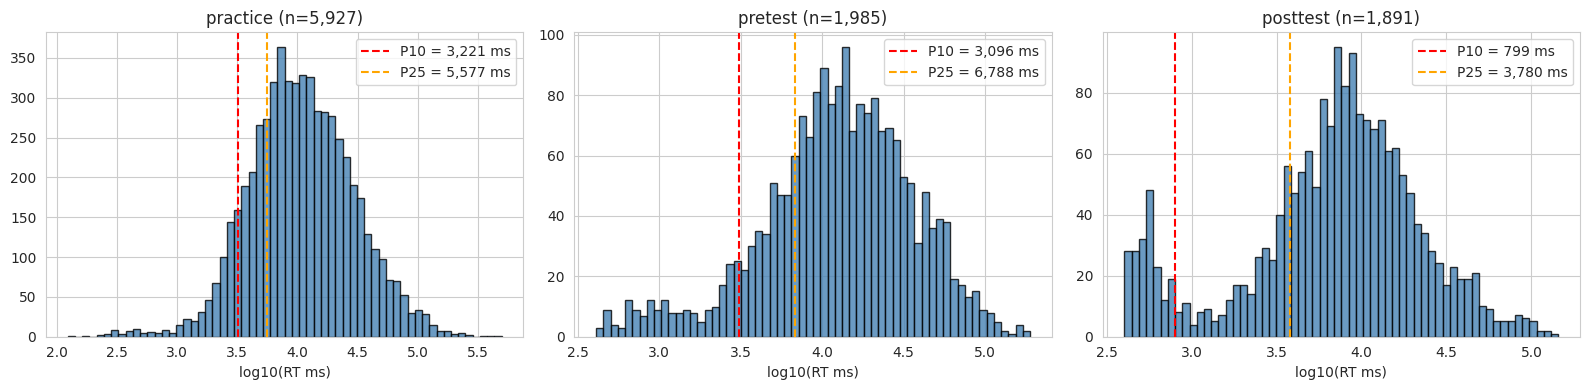

In [163]:
print("="*60)
print(f"Duplicate _id              : {df_raw['_id'].duplicated().sum()}")
print(f"Missing userId             : {df_raw['userId'].isna().sum()}")
print(f"Missing responseTimeMs     : {df_raw['responseTimeMs'].isna().sum()}")
print(f"RT ≤ 0                     : {(df_raw['responseTimeMs'] <= 0).sum()}")
print("="*60)

# Response time distribution by session type
print("\nResponse Time per Session Type:")
for st in ['practice','pre-test','post-test']:
    sub = df_raw[df_raw['sessionType'] == st]['responseTimeMs']
    if len(sub) == 0: continue
    print(f"  {st:<10} | n={len(sub):>5} | "
          f"P10={sub.quantile(.10):>7.0f}ms | "
          f"median={sub.median():>7.0f}ms | "
          f"P90={sub.quantile(.90):>8.0f}ms")

# Visualize response time by session type
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, st in zip(axes, ['practice', 'pretest', 'posttest']):
    sub = df_raw[df_raw['sessionType'] == st]['responseTimeMs']
    if len(sub) == 0:
        ax.set_title(f'{st} (no data)')
        ax.axis('off')
        continue

    p10 = sub.quantile(0.10)
    p25 = sub.quantile(0.25)

    ax.hist(np.log10(sub.clip(lower=1)), bins=60,
            color='steelblue', edgecolor='k', alpha=0.8)

    ax.axvline(np.log10(p10), color='red', linestyle='--',
               label=f'P10 = {p10:,.0f} ms')
    ax.axvline(np.log10(p25), color='orange', linestyle='--',
               label=f'P25 = {p25:,.0f} ms')

    ax.set_title(f'{st} (n={len(sub):,})')
    ax.set_xlabel('log10(RT ms)')
    ax.legend()

plt.tight_layout()
plt.show()

## 3. INDIVIDUAL USER ANALYSIS

In [168]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Convert Firestore timestamp to datetime
df_raw['timestamp'] = pd.to_datetime(df_raw['timestamp._seconds'], unit='s')

print("Data time range:")
print(f"  Start    : {df_raw['timestamp'].min()}")
print(f"  End      : {df_raw['timestamp'].max()}")
print(f"  Duration : {(df_raw['timestamp'].max() - df_raw['timestamp'].min()).days} days")

Data time range:
  Start    : 2026-11-19 00:08:46
  End      : 2026-11-19 05:57:29
  Duration : 0 days


In [169]:
def build_student_summary(df):
    rows = []
    for uid, g in df.groupby('userId'):
        row = {'userId': uid, 'total_logs': len(g)}
        for st in ['pretest', 'practice', 'posttest']:
            sg = g[g['sessionType'] == st].sort_values('timestamp')
            row[f'{st}_n'] = len(sg)
            if len(sg) > 0:
                row[f'{st}_acc']     = round(sg['isCorrect'].mean() * 100, 1)
                row[f'{st}_med_rt']  = int(sg['responseTimeMs'].median())
                row[f'{st}_pct_fast'] = round((sg['responseTimeMs'] < 2000).mean() * 100, 1)
                row[f'{st}_dur_min'] = round(
                    (sg['timestamp'].max() - sg['timestamp'].min()).total_seconds() / 60, 1)
            else:
                row[f'{st}_acc'] = row[f'{st}_med_rt'] = np.nan
                row[f'{st}_pct_fast'] = row[f'{st}_dur_min'] = np.nan
        rows.append(row)
    return pd.DataFrame(rows).sort_values('total_logs', ascending=False).reset_index(drop=True)

summary = build_student_summary(df_raw)

print(f"Total students: {len(summary)}")
print(f"With pretest  : {summary['pretest_n'].gt(0).sum()}")
print(f"With practice : {summary['practice_n'].gt(0).sum()}")
print(f"With posttest : {summary['posttest_n'].gt(0).sum()}")
print(f"With all three: {(summary[['pretest_n','practice_n','posttest_n']] > 0).all(axis=1).sum()}")


Total students: 64
With pretest  : 64
With practice : 64
With posttest : 61
With all three: 61


In [204]:
from matplotlib import cm

# Consistent KC-to-color mapping across all 64 plots
ALL_KCS = sorted(df_raw['kcId'].dropna().unique())
cmap20 = cm.get_cmap('tab20')
KC_COLORS = {kc: cmap20(i % 20) for i, kc in enumerate(ALL_KCS)}

print(f"Total unique KCs: {len(ALL_KCS)}")
for kc in ALL_KCS[:10]:
    print(f"  {kc}")

Total unique KCs: 6
  KC-01
  KC-02
  KC-03
  KC-04
  KC-05
  KC-06


/tmp/ipykernel_6850/2065183719.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap20 = cm.get_cmap('tab20')


In [205]:
import matplotlib.gridspec as gridspec

COLOR_OK   = '#27ae60'
COLOR_FAIL = '#e74c3c'

def plot_student_full(df, user_id, save_path=None, show_step_id=True):
    """
    6 rows (RT + KC ribbon per session).
    - Colored points: green = correct, red = incorrect
    - Labels above points: kcId (e.g., "05")
    - Red circles: rapid guesses (< P10)
    - Bottom ribbon: KC sequence per step (labels at transitions)
    """
    user_data = df[df['userId'] == user_id]

    fig = plt.figure(figsize=(15, 14))
    gs = fig.add_gridspec(6, 1, height_ratios=[4, 0.7, 4, 0.7, 4, 0.7], hspace=0.45)

    sessions = ['pretest', 'practice', 'posttest']
    axes_rt  = [fig.add_subplot(gs[0]), fig.add_subplot(gs[2]), fig.add_subplot(gs[4])]
    axes_rib = [fig.add_subplot(gs[1]), fig.add_subplot(gs[3]), fig.add_subplot(gs[5])]

    for st, ax_rt, ax_rib in zip(sessions, axes_rt, axes_rib):
        sg = user_data[user_data['sessionType'] == st].sort_values('timestamp').reset_index(drop=True)

        if len(sg) == 0:
            ax_rt.text(0.5, 0.5, f'{st.upper()}: no data',
                       transform=ax_rt.transAxes, ha='center', va='center',
                       fontsize=14, color='gray', style='italic')
            ax_rt.set_xticks([]); ax_rt.set_yticks([])
            ax_rib.axis('off')
            continue

        x = np.arange(len(sg))
        y = sg['responseTimeMs'].values
        colors_pt = [COLOR_OK if c else COLOR_FAIL for c in sg['isCorrect']]

        # ---- Response time plot ----
        ax_rt.plot(x, y, color='#bdc3c7', alpha=0.4, linewidth=1, zorder=1)
        ax_rt.scatter(x, y, c=colors_pt, s=80, edgecolors='black',
                      linewidths=0.6, zorder=3)

        # KC labels above each point
        for xi, yi, kc in zip(x, y, sg['kcId']):
            label = kc.replace('KC-', '') if isinstance(kc, str) else '?'
            ax_rt.annotate(label, (xi, yi), xytext=(0, 9),
                           textcoords='offset points', fontsize=6.5,
                           ha='center', va='bottom',
                           color=KC_COLORS.get(kc, 'black'), fontweight='bold')

        # Highlight rapid guesses
        p10 = ST_P10[st]
        rapid_mask = y < p10
        if rapid_mask.any():
            ax_rt.scatter(x[rapid_mask], y[rapid_mask], s=260, facecolors='none',
                          edgecolors='red', linewidths=2, zorder=4)

        ax_rt.axhline(p10,          color='red',    linestyle='--', alpha=0.5, label=f'P10={p10:.0f}ms')
        ax_rt.axhline(ST_P25[st],   color='orange', linestyle='--', alpha=0.5, label=f'P25={ST_P25[st]:.0f}ms')

        acc     = sg['isCorrect'].mean() * 100
        med_rt  = sg['responseTimeMs'].median()
        dur_min = (sg['timestamp'].max() - sg['timestamp'].min()).total_seconds() / 60
        n_rapid = int(rapid_mask.sum())
        n_kc    = sg['kcId'].nunique()
        n_q     = sg['questionId'].nunique()

        ax_rt.set_yscale('log')
        ax_rt.set_ylabel('Response Time (ms, log)')
        ax_rt.set_title(
            f'{st.upper()} — n={len(sg)}, accuracy={acc:.1f}%, median RT={med_rt:.0f}ms, '
            f'duration={dur_min:.1f}min, unique KCs={n_kc}, questions={n_q}, rapid guesses={n_rapid}',
            fontsize=11, fontweight='bold', loc='left')
        ax_rt.grid(True, alpha=0.3, which='both')
        ax_rt.set_ylim(max(50, y.min() * 0.4), y.max() * 2.5)
        ax_rt.legend(loc='upper right', fontsize=7, framealpha=0.9)
        ax_rt.set_xlim(-0.5, len(sg) - 0.5)

        # ---- KC ribbon ----
        prev_kc = None
        for j, kc in enumerate(sg['kcId']):
            ax_rib.barh(0, 1, left=j, color=KC_COLORS.get(kc, 'gray'),
                        edgecolor='white', linewidth=0.3)
            if kc != prev_kc:
                label = kc.replace('KC-', '') if isinstance(kc, str) else '?'
                ax_rib.text(j + 0.5, 0, label, ha='center', va='center',
                            fontsize=7, fontweight='bold', color='white')
            prev_kc = kc

        # Mark question boundaries (when questionId changes)
        q_change = (sg['questionId'] != sg['questionId'].shift()).values
        for j, change in enumerate(q_change):
            if change and j > 0:
                ax_rib.axvline(j - 0.5, color='black', linestyle=':', linewidth=1.2, alpha=0.8)

        ax_rib.set_ylim(-0.5, 0.5)
        ax_rib.set_yticks([])
        ax_rib.set_ylabel('KC', rotation=0, fontsize=9, labelpad=20)
        ax_rib.set_xlabel('Step order (sorted by timestamp)  ·  black dotted line = new question')
        ax_rib.set_xlim(-0.5, len(sg) - 0.5)

    # Global legend
    legend_handles = [
        plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=COLOR_OK,
                   markersize=10, label='Correct'),
        plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=COLOR_FAIL,
                   markersize=10, label='Incorrect'),
        plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='none',
                   markeredgecolor='red', markeredgewidth=2,
                   markersize=14, label='Rapid guess (<P10)'),
    ]
    fig.legend(handles=legend_handles, loc='upper right', ncol=3,
               fontsize=9, bbox_to_anchor=(0.98, 0.998))
    fig.suptitle(f'Student: {user_id}  (total {len(user_data)} logs)',
                 fontsize=14, fontweight='bold', y=1.005)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=100, bbox_inches='tight')
        plt.close(fig)

/tmp/ipykernel_6850/3722159250.py:116: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


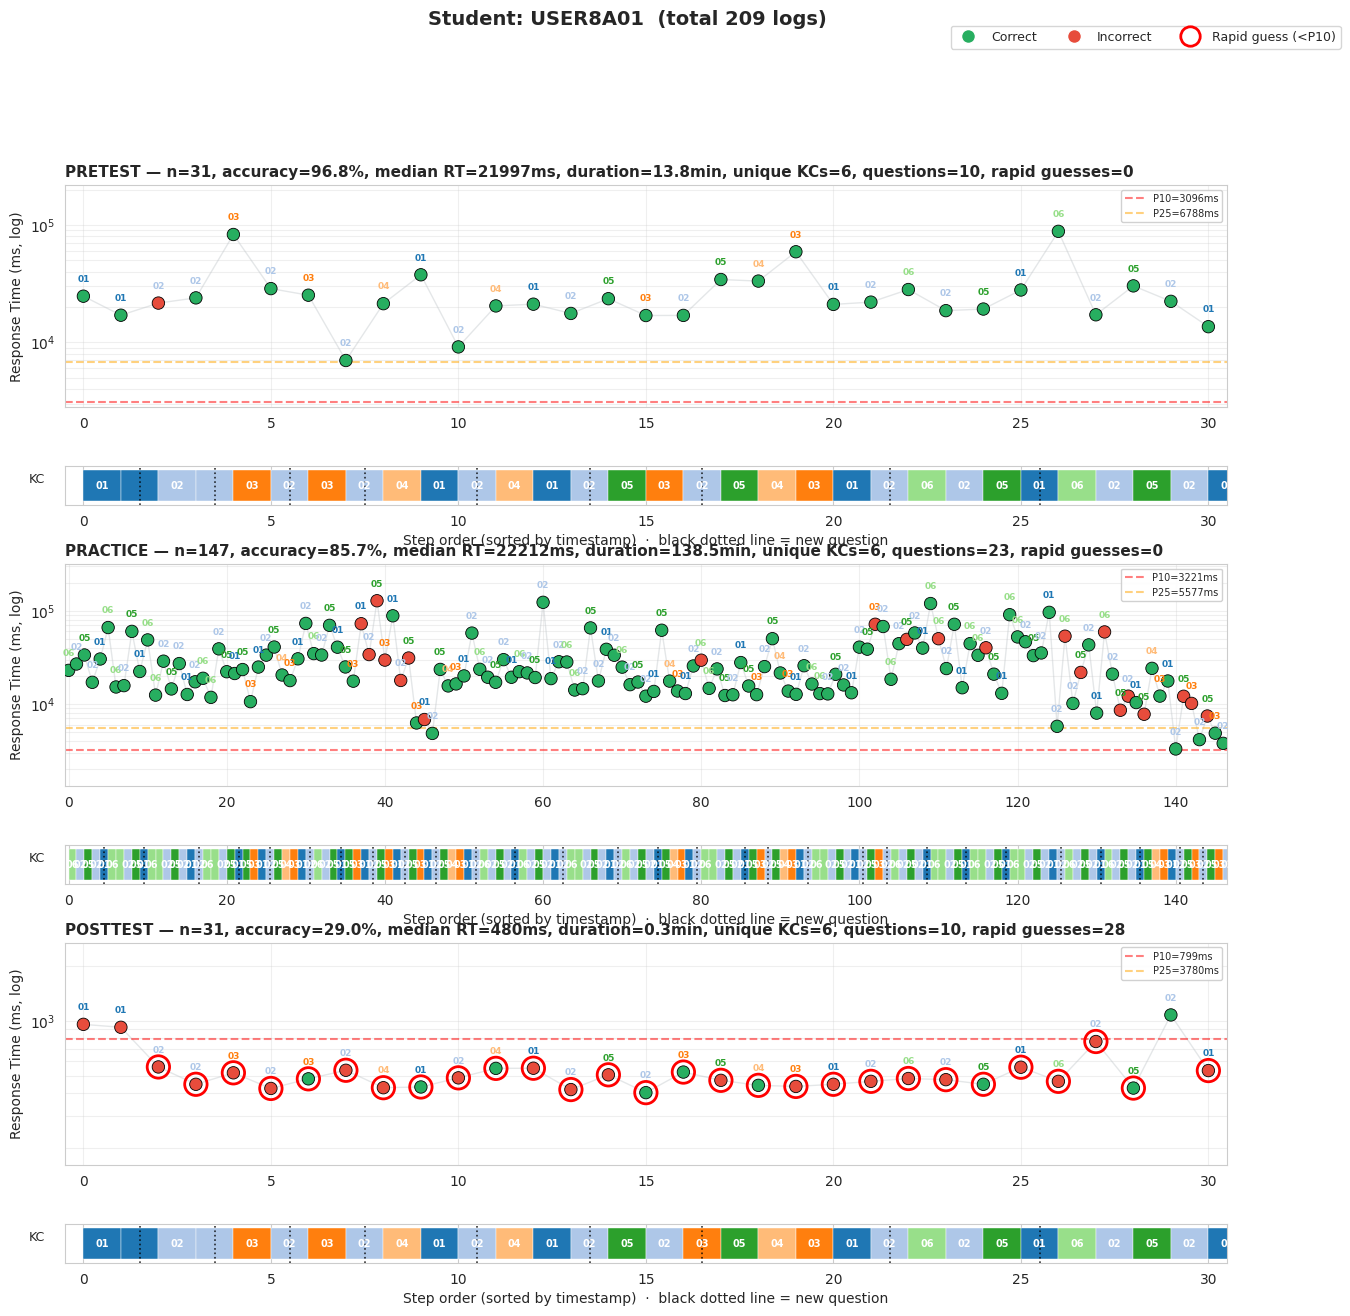

In [206]:
with_all = (summary[['pretest_n','practice_n','posttest_n']] > 0).all(axis=1)
sample_uid = summary[with_all].iloc[0]['userId']
plot_student_full(df_raw, sample_uid)

In [209]:
# This code saves all 64 student graphs, exports detailed step-level data for all students,
# and exports a summary of each student's performance by KC.

# import os
# OUT_DIR = '/content/drive/MyDrive/Skripsi-InkSkyCat/per_student_full/'
# os.makedirs(OUT_DIR, exist_ok=True)

# # 1. Save 64 student graphs
# print(f"Saving {len(summary)} graphs ...")
# for i, uid in enumerate(summary['userId'], 1):
#     plot_student_full(df_raw, uid, save_path=f'{OUT_DIR}{i:02d}_{uid}.png')
#     if i % 10 == 0 or i == len(summary):
#         print(f"  {i}/{len(summary)} completed")

# # 2. Save detailed step-level data (long format) — all students, all sessions
# all_steps = []
# for uid in summary['userId']:
#     for st in ['pretest', 'practice', 'posttest']:
#         d = get_step_detail(df_raw, uid, st)
#         if len(d):
#             d.insert(0, 'sessionType', st)
#             d.insert(0, 'userId', uid)
#             all_steps.append(d)

# step_long = pd.concat(all_steps, ignore_index=True)
# step_long.to_csv(OUT_DIR + 'all_steps_detail.csv', index=False)
# print(f"✅ all_steps_detail.csv  ({len(step_long):,} rows)")

# # 3. Save KC summary for all students
# kc_all = []
# for uid in summary['userId']:
#     k = get_student_kc_summary(df_raw, uid)
#     if len(k):
#         k.insert(0, 'userId', uid)
#         kc_all.append(k)

# kc_summary = pd.concat(kc_all, ignore_index=True)
# kc_summary.to_csv(OUT_DIR + 'all_kc_summary.csv', index=False)
# print(f"✅ all_kc_summary.csv    ({len(kc_summary):,} rows)")

## 4. DATA CLEANING



In [235]:
# Manually excluded users (human review)
EXCLUDE_USERS = [
    'USER712', 'USER714', 'USER715', 'USER720', 'USER726',
    'USER8A01', 'USER8A04', 'USER8A17', 'USER8A20',
    'USER8B02', 'USER8B05', 'USER8B10', 'USER8B12', 'USER8B13',
]

# Remove excluded users from the flagged dataset (df = df_flagged from the previous pipeline)
df_clean = df[~df['userId'].isin(EXCLUDE_USERS)].copy()

# Summary
n_before = len(df)
n_after  = len(df_clean)
n_removed_rows = n_before - n_after
n_removed_users = df['userId'].nunique() - df_clean['userId'].nunique()

print(f"Logs before   : {n_before:,}")
print(f"Logs after    : {n_after:,}")
print(f"Logs removed  : {n_removed_rows:,} ({n_removed_rows/n_before*100:.1f}%)")
print(f"Users before  : {df['userId'].nunique()}")
print(f"Users after   : {df_clean['userId'].nunique()}")
print(f"Users removed : {n_removed_users}")

print("\nDistribution by session:")
print(f"{'':<12}{'Before':>10}{'After':>10}{'Removed':>10}")
for st in ['practice', 'pretest', 'posttest']:
    a = (df['sessionType'] == st).sum()
    b = (df_clean['sessionType'] == st).sum()
    print(f"{st:<12}{a:>10,}{b:>10,}{a-b:>10,}")

Logs before   : 9,803
Logs after    : 8,285
Logs removed  : 1,518 (15.5%)
Users before  : 64
Users after   : 51
Users removed : 13

Distribution by session:
                Before     After   Removed
practice         5,927     5,122       805
pretest          1,985     1,582       403
posttest         1,891     1,581       310


In [236]:
# ============================================
# Prepare df_clean
# ============================================
if 'validity_status' in df_clean.columns:
    df_bkt = df_clean[df_clean['validity_status'] == 'Valid'].copy()
    print("✅ Using validity_status == 'Valid' filter")
else:
    df_bkt = df_clean.copy()
    print("ℹ️ Column 'validity_status' not found → all rows are considered valid")

# ============================================
# Convert Data Types
# ============================================
df_bkt['timestamp'] = (
    df_bkt['timestamp._seconds']
    + df_bkt['timestamp._nanoseconds'] / 1e9
)

df_bkt['isCorrect'] = df_bkt['isCorrect'].astype(int)

# Remove unnecessary columns
df_bkt = df_bkt.drop(
    columns=[c for c in ['pLBefore', 'pLAfter'] if c in df_bkt.columns]
)

# Remove exact duplicate IDs
df_bkt = df_bkt.drop_duplicates(subset=['_id'])

# ============================================
# Remove Duplicate Logs
# Keep the earliest log for each answered step
# ============================================
duplicate_cols = [
    'userId',
    'nodeId',
    'questionId',
    'questionStepId'
]

# Sort by original timestamp (earliest first)
df_bkt = df_bkt.sort_values(
    ['timestamp._seconds', 'timestamp._nanoseconds']
).copy()

# Identify duplicate logs for audit
df_duplicates = df_bkt[
    df_bkt.duplicated(
        subset=duplicate_cols,
        keep='first'
    )
].copy()

# Keep only the earliest log
before_dedup = len(df_bkt)

df_bkt = df_bkt.drop_duplicates(
    subset=duplicate_cols,
    keep='first'
).copy()

after_dedup = len(df_bkt)

print("\n" + "="*60)
print("DUPLICATE LOG CLEANING")
print("="*60)
print(f"Rows before deduplication : {before_dedup}")
print(f"Rows after deduplication  : {after_dedup}")
print(f"Duplicates removed        : {before_dedup - after_dedup}")
print("="*60)

# ============================================
# Split by sessionType
# ============================================
df_practice = df_bkt[df_bkt['sessionType'] == 'practice'].copy()
df_pretest  = df_bkt[df_bkt['sessionType'] == 'pretest'].copy()
df_posttest = df_bkt[df_bkt['sessionType'] == 'posttest'].copy()
df_exam     = df_bkt[df_bkt['sessionType'].isin(['pretest', 'posttest'])].copy()

print("\n" + "="*60)
print("FINAL DATASET")
print("="*60)
print(f"Practice : {len(df_practice):>5} rows, {df_practice['userId'].nunique()} users")
print(f"Pretest  : {len(df_pretest):>5} rows, {df_pretest['userId'].nunique()} users")
print(f"Posttest : {len(df_posttest):>5} rows, {df_posttest['userId'].nunique()} users")
print(f"Exam     : {len(df_exam):>5} rows, {df_exam['userId'].nunique()} users")
print("="*60)

# ============================================
# Save CSV files
# ============================================
BASE = '/content/drive/MyDrive/Skripsi-InkSkyCat/'

df_bkt.to_csv(BASE + 'CLEAN_all.csv', index=False)
df_practice.to_csv(BASE + 'CLEAN_practice.csv', index=False)
df_pretest.to_csv(BASE + 'CLEAN_pretest.csv', index=False)
df_posttest.to_csv(BASE + 'CLEAN_posttest.csv', index=False)

# Save removed duplicate logs for audit
df_duplicates.to_csv(BASE + 'CLEAN_duplicates_removed.csv', index=False)

print("\n✅ CLEAN_all.csv")
print("✅ CLEAN_practice.csv")
print("✅ CLEAN_pretest.csv")
print("✅ CLEAN_posttest.csv")
print("✅ CLEAN_duplicates_removed.csv")

ℹ️ Column 'validity_status' not found → all rows are considered valid

DUPLICATE LOG CLEANING
Rows before deduplication : 8285
Rows after deduplication  : 8281
Duplicates removed        : 4

FINAL DATASET
Practice :  5119 rows, 51 users
Pretest  :  1581 rows, 51 users
Posttest :  1581 rows, 51 users
Exam     :  3162 rows, 51 users

✅ CLEAN_all.csv
✅ CLEAN_practice.csv
✅ CLEAN_pretest.csv
✅ CLEAN_posttest.csv
✅ CLEAN_duplicates_removed.csv


## 5. LEARNING GAIN

### 5.1. DATASET VALIDATION

In [219]:

import pandas as pd
import numpy as np

# ============================================
# 1. BASIC DATASET VALIDATION
# ============================================

EXPECTED_USERS = 51
EXPECTED_STEPS = 31

print("=" * 65)
print("1. BASIC DATASET VALIDATION")
print("=" * 65)

print(f"Pretest  : {len(df_pretest):,} logs")
print(f"Posttest : {len(df_posttest):,} logs")

print(f"Pretest users  : {df_pretest['userId'].nunique()}")
print(f"Posttest users : {df_posttest['userId'].nunique()}")

print(f"Expected logs per session: {EXPECTED_USERS * EXPECTED_STEPS:,}")

# ============================================
# 2. PARTICIPANT COMPLETENESS
# ============================================

print("\n" + "=" * 65)
print("2. PARTICIPANT COMPLETENESS")
print("=" * 65)

pre_users = set(df_pretest['userId'].unique())
post_users = set(df_posttest['userId'].unique())

print("Users in both sessions :", len(pre_users & post_users))
print("Only in pretest        :", len(pre_users - post_users))
print("Only in posttest       :", len(post_users - pre_users))

# ============================================
# 3. LOG COMPLETENESS PER STUDENT
# ============================================

print("\n" + "=" * 65)
print("3. LOG COMPLETENESS PER STUDENT")
print("=" * 65)

pre_count = df_pretest.groupby('userId').size()
post_count = df_posttest.groupby('userId').size()

completion = pd.DataFrame({
    'pretest_logs': pre_count,
    'posttest_logs': post_count
}).fillna(0).astype(int)

completion['pretest_complete'] = (
    completion['pretest_logs'] == EXPECTED_STEPS
)

completion['posttest_complete'] = (
    completion['posttest_logs'] == EXPECTED_STEPS
)

completion['both_complete'] = (
    completion['pretest_complete'] &
    completion['posttest_complete']
)

print(completion.describe())

print("\nIncomplete students:")
print(completion[~completion['both_complete']])

print("\nFully complete students:",
      completion['both_complete'].sum())

# ============================================
# 4. KC DISTRIBUTION
# ============================================

print("\n" + "=" * 65)
print("4. KC DISTRIBUTION")
print("=" * 65)

kc_pre = (
    df_pretest['kcId']
    .value_counts()
    .sort_index()
)

kc_post = (
    df_posttest['kcId']
    .value_counts()
    .sort_index()
)

kc_distribution = pd.DataFrame({
    'pretest_logs': kc_pre,
    'posttest_logs': kc_post
}).fillna(0).astype(int)

kc_distribution['pretest_pct'] = (
    kc_distribution['pretest_logs'] /
    len(df_pretest) * 100
)

kc_distribution['posttest_pct'] = (
    kc_distribution['posttest_logs'] /
    len(df_posttest) * 100
)

kc_distribution['same_count'] = (
    kc_distribution['pretest_logs'] ==
    kc_distribution['posttest_logs']
)

print(kc_distribution.round(2))

# ============================================
# 5. UNIQUE STEP STRUCTURE
# ============================================

print("\n" + "=" * 65)
print("5. UNIQUE STEP STRUCTURE")
print("=" * 65)

for name, data in [
    ('PRETEST', df_pretest),
    ('POSTTEST', df_posttest)
]:
    print(f"\n{name}")

    print("Unique questions:",
          data['questionId'].nunique())

    print("Unique steps:",
          data[['questionId', 'questionStepId']].drop_duplicates().shape[0])

    print("KC per step:")

    step_kc = (
        data.groupby(['questionId', 'questionStepId'])['kcId']
        .nunique()
    )

    print("Steps with exactly one KC:",
          (step_kc == 1).sum())

    print("Steps with multiple KCs:",
          (step_kc > 1).sum())

    print("Steps without KC:",
          data['kcId'].isna().sum())

# ============================================
# 6. ANSWER VALIDITY
# ============================================

print("\n" + "=" * 65)
print("6. ANSWER VALIDITY")
print("=" * 65)

for name, data in [
    ('PRETEST', df_pretest),
    ('POSTTEST', df_posttest)
]:
    print(f"\n{name}")

    print("isCorrect distribution:")
    print(data['isCorrect'].value_counts(dropna=False))

    print("Missing selectedOption:",
          data['selectedOption'].isna().sum())

    print("Missing isCorrect:",
          data['isCorrect'].isna().sum())

# ============================================
# 7. SUMMARY
# ============================================

print("\n" + "=" * 65)
print("7. VALIDATION SUMMARY")
print("=" * 65)

checks = {
    '51 users in both sessions':
        len(pre_users & post_users) == EXPECTED_USERS,

    '31 logs per student in both sessions':
        completion['both_complete'].all(),

    'Same number of logs per KC':
        kc_distribution['same_count'].all(),

    'No multiple-KC steps':
        all(
            data.groupby(
                ['questionId', 'questionStepId']
            )['kcId'].nunique().max() == 1
            for data in [df_pretest, df_posttest]
        ),

    'No missing correctness values':
        all(
            data['isCorrect'].notna().all()
            for data in [df_pretest, df_posttest]
        )
}

for label, passed in checks.items():
    print(f"{'PASS' if passed else 'CHECK'} - {label}")


1. BASIC DATASET VALIDATION
Pretest  : 1,581 logs
Posttest : 1,581 logs
Pretest users  : 51
Posttest users : 51
Expected logs per session: 1,581

2. PARTICIPANT COMPLETENESS
Users in both sessions : 51
Only in pretest        : 0
Only in posttest       : 0

3. LOG COMPLETENESS PER STUDENT
       pretest_logs  posttest_logs
count          51.0           51.0
mean           31.0           31.0
std             0.0            0.0
min            31.0           31.0
25%            31.0           31.0
50%            31.0           31.0
75%            31.0           31.0
max            31.0           31.0

Incomplete students:
Empty DataFrame
Columns: [pretest_logs, posttest_logs, pretest_complete, posttest_complete, both_complete]
Index: []

Fully complete students: 51

4. KC DISTRIBUTION
       pretest_logs  posttest_logs  pretest_pct  posttest_pct  same_count
kcId                                                                     
KC-01           357            357        22.58         22.5

### 5.2. BUILD STUDENT SCORE DATASET

In [239]:
KC_ORDER = [f'KC-{i:02d}' for i in range(1, 7)]

def get_step_kc_counts(data):
    # Get unique steps within a session
    steps = data[
        ['questionId', 'questionStepId', 'kcId']
    ].drop_duplicates()

    # Ensure each step is assigned to exactly one KC
    kc_per_step = steps.groupby(
        ['questionId', 'questionStepId']
    )['kcId'].nunique()

    assert (kc_per_step == 1).all(), (
        "Some steps are assigned to more than one KC!"
    )

    # Count unique steps for each KC
    return (
        steps.groupby('kcId')
        .size()
        .reindex(KC_ORDER, fill_value=0)
    )


# Count steps per KC for each session
pre_kc_steps = get_step_kc_counts(df_pretest)
post_kc_steps = get_step_kc_counts(df_posttest)

# Compare the structure based on the number of steps per KC
kc_structure = pd.DataFrame({
    'pretest_steps': pre_kc_steps,
    'posttest_steps': post_kc_steps
})

print("Comparison of step counts per KC:")
display(kc_structure)

# Validate the total number of unique steps
pre_total_steps = df_pretest[
    ['questionId', 'questionStepId']
].drop_duplicates().shape[0]

post_total_steps = df_posttest[
    ['questionId', 'questionStepId']
].drop_duplicates().shape[0]

assert pre_total_steps == 31
assert post_total_steps == 31
assert (pre_kc_steps == post_kc_steps).all()

print("PASS - The number of steps per KC is identical in the pretest and posttest.")
print("PASS - Each session contains 31 unique steps.")

Comparison of step counts per KC:


,pretest_steps,posttest_steps
kcId,,
KC-01,7,7
KC-02,11,11
KC-03,4,4
KC-04,3,3
KC-05,4,4
KC-06,2,2


PASS - The number of steps per KC is identical in the pretest and posttest.
PASS - Each session contains 31 unique steps.


In [238]:
# ============================================
# STAGE 2 - CALCULATE STUDENT SCORES
# ============================================

KC_ORDER = [f'KC-{i:02d}' for i in range(1, 7)]


def calculate_scores(data, session_name):
    # Ensure each row represents one unique step
    steps = data.drop_duplicates(
        subset=['userId', 'questionId', 'questionStepId']
    ).copy()

    # Calculate each student's overall score
    overall = (
        steps.groupby('userId')['isCorrect']
        .agg(correct='sum', total='count')
        .reset_index()
    )

    overall[f'{session_name}_score'] = (
        overall['correct'] / overall['total'] * 100
    )

    overall = overall[
        ['userId', 'correct', 'total', f'{session_name}_score']
    ].rename(columns={
        'correct': f'{session_name}_correct',
        'total': f'{session_name}_total'
    })

    # Calculate scores for each KC
    kc_scores = (
        steps.groupby(['userId', 'kcId'])['isCorrect']
        .agg(correct='sum', total='count')
        .reset_index()
    )

    kc_scores[f'{session_name}_score'] = (
        kc_scores['correct'] / kc_scores['total'] * 100
    )

    # Reshape into one row per student
    kc_wide = kc_scores.pivot(
        index='userId',
        columns='kcId',
        values=f'{session_name}_score'
    )

    kc_wide.columns = [
        f'{session_name}_{kc}_score'
        for kc in kc_wide.columns
    ]

    kc_wide = kc_wide.reset_index()

    return overall.merge(kc_wide, on='userId')


# Calculate pretest and posttest scores
df_pre_scores = calculate_scores(df_pretest, 'pretest')
df_post_scores = calculate_scores(df_posttest, 'posttest')

# Merge scores by student
df_scores = df_pre_scores.merge(
    df_post_scores,
    on='userId',
    how='inner',
    validate='one_to_one'
)

# Calculate overall gain
df_scores['overall_gain'] = (
    df_scores['posttest_score'] -
    df_scores['pretest_score']
)

# Calculate gain for each KC
for kc in KC_ORDER:
    df_scores[f'{kc}_gain'] = (
        df_scores[f'posttest_{kc}_score'] -
        df_scores[f'pretest_{kc}_score']
    )


# ============================================
# VALIDATION
# ============================================

assert len(df_scores) == 51
assert df_scores['userId'].nunique() == 51

print("PASS - 51 students included")
print("PASS - Each student has paired pretest-posttest scores")


# ============================================
# DISPLAY RESULTS
# ============================================

display(df_scores.head())

# Overall score summary
print("\nOverall score summary:")
display(
    df_scores[
        ['pretest_score', 'posttest_score', 'overall_gain']
    ].describe().round(2)
)

# KC score summary
kc_summary = []

for kc in KC_ORDER:
    kc_summary.append({
        'KC': kc,
        'Pretest Mean': df_scores[f'pretest_{kc}_score'].mean(),
        'Posttest Mean': df_scores[f'posttest_{kc}_score'].mean(),
        'Mean Gain': df_scores[f'{kc}_gain'].mean()
    })

df_kc_summary = pd.DataFrame(kc_summary).round(2)

print("\nKC score summary:")
display(df_kc_summary)


# Save results
df_scores.to_csv(
    'ANALYSIS_student_scores.csv',
    index=False
)

df_kc_summary.to_csv(
    'ANALYSIS_kc_summary.csv',
    index=False
)

PASS - 51 students included
PASS - Each student has paired pretest-posttest scores


,userId,pretest_correct,pretest_total,pretest_score,pretest_KC-01_score,pretest_KC-02_score,pretest_KC-03_score,pretest_KC-04_score,pretest_KC-05_score,pretest_KC-06_score,...,posttest_KC-04_score,posttest_KC-05_score,posttest_KC-06_score,overall_gain,KC-01_gain,KC-02_gain,KC-03_gain,KC-04_gain,KC-05_gain,KC-06_gain
0,USER701,23,31,74.193548,71.428571,100.000000,75.0,66.666667,25.0,50.0,...,100.000000,100.0,100.0,25.806452,28.571429,0.000000,25.0,33.333333,75.0,50.0
1,USER702,18,31,58.064516,14.285714,100.000000,50.0,100.000000,25.0,0.0,...,0.000000,0.0,50.0,-9.677419,14.285714,-18.181818,25.0,-100.000000,-25.0,50.0
2,USER703,18,31,58.064516,57.142857,81.818182,75.0,0.000000,50.0,0.0,...,33.333333,0.0,0.0,6.451613,28.571429,18.181818,-25.0,33.333333,-50.0,0.0
3,USER704,29,31,93.548387,100.000000,100.000000,100.0,100.000000,50.0,100.0,...,100.000000,50.0,100.0,-6.451613,-28.571429,0.000000,0.0,0.000000,0.0,0.0
4,USER705,23,31,74.193548,71.428571,90.909091,100.0,66.666667,0.0,100.0,...,100.000000,50.0,50.0,12.903226,28.571429,0.000000,0.0,33.333333,50.0,-50.0



Overall score summary:


,pretest_score,posttest_score,overall_gain
count,51.00,51.00,51.00
mean,68.82,78.81,9.99
std,20.50,16.81,13.61
min,19.35,41.94,-12.90
25%,54.84,66.13,0.00
50%,70.97,80.65,9.68
75%,87.10,93.55,19.35
max,100.00,100.00,51.61



KC score summary:


,KC,Pretest Mean,Posttest Mean,Mean Gain
0,KC-01,69.19,79.83,10.64
1,KC-02,81.46,89.66,8.20
2,KC-03,66.18,79.90,13.73
3,KC-04,58.82,73.20,14.38
4,KC-05,50.49,58.33,7.84
5,KC-06,54.90,62.75,7.84


### 5.3. NORMALITY TEST - OVERALL GAIN

In [240]:
import pandas as pd
import numpy as np
from scipy.stats import shapiro

# ============================================
# NORMALITY TEST - OVERALL GAIN
# ============================================

overall_gain = df_scores['overall_gain'].dropna()

stat, p_value = shapiro(overall_gain)

print("Shapiro-Wilk Test: Overall Gain")
print(f"Statistic : {stat:.4f}")
print(f"P-value   : {p_value:.4f}")

if p_value > 0.05:
    print("Interpretation: There is insufficient evidence to reject the assumption of normality.")
else:
    print("Interpretation: The gain distribution shows a departure from normality.")


# ============================================
# NORMALITY TEST - EACH KC GAIN
# ============================================

kc_normality = []

for kc in KC_ORDER:
    gain = df_scores[f'{kc}_gain'].dropna()

    stat, p_value = shapiro(gain)

    kc_normality.append({
        'KC': kc,
        'Shapiro Statistic': stat,
        'P-value': p_value,
        'Normality (alpha=0.05)': (
            'Fail to reject normality'
            if p_value > 0.05
            else 'Departure from normality'
        )
    })

df_normality = pd.DataFrame(kc_normality)

print("\nNormality Test - Each KC:")
display(df_normality.round(4))

Shapiro-Wilk Test: Overall Gain
Statistic : 0.9545
P-value   : 0.0489
Interpretation: The gain distribution shows a departure from normality.

Normality Test - Each KC:


,KC,Shapiro Statistic,P-value,Normality (alpha=0.05)
0,KC-01,0.9592,0.0772,Fail to reject normality
1,KC-02,0.7154,0.0000,Departure from normality
2,KC-03,0.8541,0.0000,Departure from normality
3,KC-04,0.9290,0.0046,Departure from normality
4,KC-05,0.9311,0.0055,Departure from normality
5,KC-06,0.8789,0.0001,Departure from normality


In [241]:
def count_gain_categories(gain):
    return pd.Series({
        'Improved': (gain > 0).sum(),
        'Unchanged': (gain == 0).sum(),
        'Declined': (gain < 0).sum()
    })

print("Overall:")
display(count_gain_categories(df_scores['overall_gain']))

print("\nBy KC:")
individual_changes = pd.DataFrame({
    kc: count_gain_categories(df_scores[f'{kc}_gain'])
    for kc in KC_ORDER
}).T

display(individual_changes)

Overall:


,0
Improved,36
Unchanged,5
Declined,10



By KC:


,Improved,Unchanged,Declined
KC-01,27,12,12
KC-02,18,24,9
KC-03,21,25,5
KC-04,23,16,12
KC-05,20,18,13
KC-06,15,26,10


### 5.4. WILCOXON SIGNED-RANK TEST

In [242]:
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon, rankdata
from statsmodels.stats.multitest import multipletests


def run_wilcoxon(pre, post):
    differences = (
        np.asarray(post, dtype=float) -
        np.asarray(pre, dtype=float)
    )

    differences = differences[~np.isnan(differences)]

    # Exclude zero differences for rank-biserial calculation
    nonzero = differences[differences != 0]

    if len(nonzero) == 0:
        return {
            'N': len(differences),
            'N nonzero': 0,
            'Median Gain': 0,
            'W statistic': 0,
            'p-value': 1.0,
            'Rank-biserial': 0.0
        }

    # Wilcoxon signed-rank test
    result = wilcoxon(
        differences,
        zero_method='wilcox',
        alternative='two-sided',
        method='auto'
    )

    # Calculate rank-biserial correlation
    ranks = rankdata(np.abs(nonzero))

    positive_rank_sum = ranks[nonzero > 0].sum()
    negative_rank_sum = ranks[nonzero < 0].sum()

    rank_biserial = (
        positive_rank_sum - negative_rank_sum
    ) / (positive_rank_sum + negative_rank_sum)

    return {
        'N': len(differences),
        'N nonzero': len(nonzero),
        'Median Gain': np.median(differences),
        'W statistic': result.statistic,
        'p-value': result.pvalue,
        'Rank-biserial': rank_biserial
    }


# ============================================
# OVERALL TEST
# ============================================

overall_result = run_wilcoxon(
    df_scores['pretest_score'],
    df_scores['posttest_score']
)

df_overall_test = pd.DataFrame(
    [overall_result],
    index=['Overall']
)

print("OVERALL WILCOXON TEST")
display(df_overall_test.round(4))


# ============================================
# PER-KC TEST
# ============================================

kc_results = []

for kc in KC_ORDER:
    result = run_wilcoxon(
        df_scores[f'pretest_{kc}_score'],
        df_scores[f'posttest_{kc}_score']
    )

    result['KC'] = kc
    kc_results.append(result)

df_kc_tests = pd.DataFrame(kc_results)

# Apply Holm correction for the six KC tests
reject, p_adjusted, _, _ = multipletests(
    df_kc_tests['p-value'],
    alpha=0.05,
    method='holm'
)

df_kc_tests['p-adjusted (Holm)'] = p_adjusted
df_kc_tests['Significant'] = reject

df_kc_tests = df_kc_tests[
    [
        'KC',
        'N',
        'N nonzero',
        'Median Gain',
        'W statistic',
        'p-value',
        'p-adjusted (Holm)',
        'Rank-biserial',
        'Significant'
    ]
]

print("\nWILCOXON TEST - EACH KC")
display(df_kc_tests.round(4))

OVERALL WILCOXON TEST


,N,N nonzero,Median Gain,W statistic,p-value,Rank-biserial
Overall,51,46,9.6774,139.0,0.0,0.7428



WILCOXON TEST - EACH KC


,KC,N,N nonzero,Median Gain,W statistic,p-value,p-adjusted (Holm),Rank-biserial,Significant
0,KC-01,51,39,14.2857,191.5,0.0053,0.0265,0.5090,True
1,KC-02,51,27,0.0000,90.0,0.0164,0.0656,0.5238,False
2,KC-03,51,26,0.0000,45.0,0.0006,0.0035,0.7436,True
3,KC-04,51,35,0.0000,172.5,0.0182,0.0656,0.4524,False
4,KC-05,51,33,0.0000,188.0,0.0872,0.1743,0.3298,False
5,KC-06,51,25,0.0000,117.5,0.1962,0.1962,0.2769,False


In [225]:

print("Overall p-value:", f"{overall_result['p-value']:.10g}")

print("\nKC p-values:")
for _, row in df_kc_tests.iterrows():
    print(
        row['KC'],
        "| Raw:", f"{row['p-value']:.10g}",
        "| Holm:", f"{row['p-adjusted (Holm)']:.10g}"
    )


Overall p-value: 1.138247552e-05

KC p-values:
KC-01 | Raw: 0.005293200196 | Holm: 0.02646600098
KC-02 | Raw: 0.01640889351 | Holm: 0.06563557406
KC-03 | Raw: 0.0005871425561 | Holm: 0.003522855336
KC-04 | Raw: 0.01817288009 | Holm: 0.06563557406
KC-05 | Raw: 0.08716515438 | Holm: 0.1743303088
KC-06 | Raw: 0.1962447266 | Holm: 0.1962447266


### 5.5. DATA VISUALIZATION

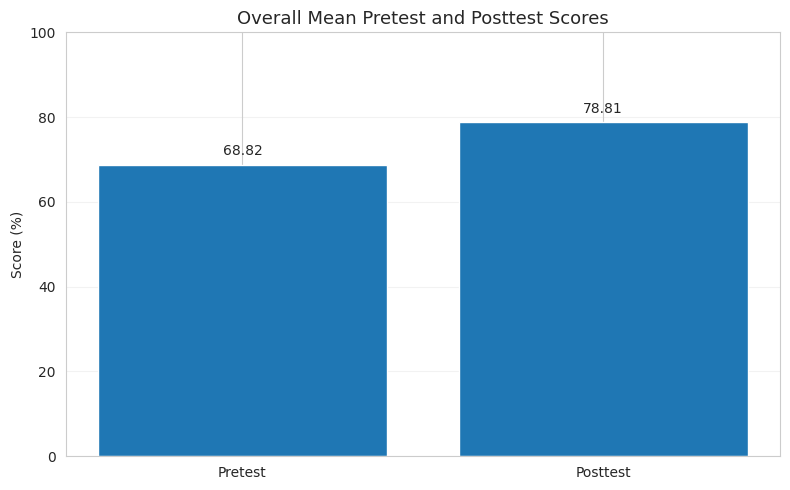

In [243]:
import matplotlib.pyplot as plt

# Data
scores = {
    'Pretest': 68.82,
    'Posttest': 78.81
}

# Plot
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    scores.keys(),
    scores.values()
)

ax.set_title(
    'Overall Mean Pretest and Posttest Scores',
    fontsize=13
)
ax.set_ylabel('Score (%)')
ax.set_ylim(0, 100)

ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)

# Add value labels
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1.5,
        f'{height:.2f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.savefig(
    'grafik_skor_keseluruhan.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

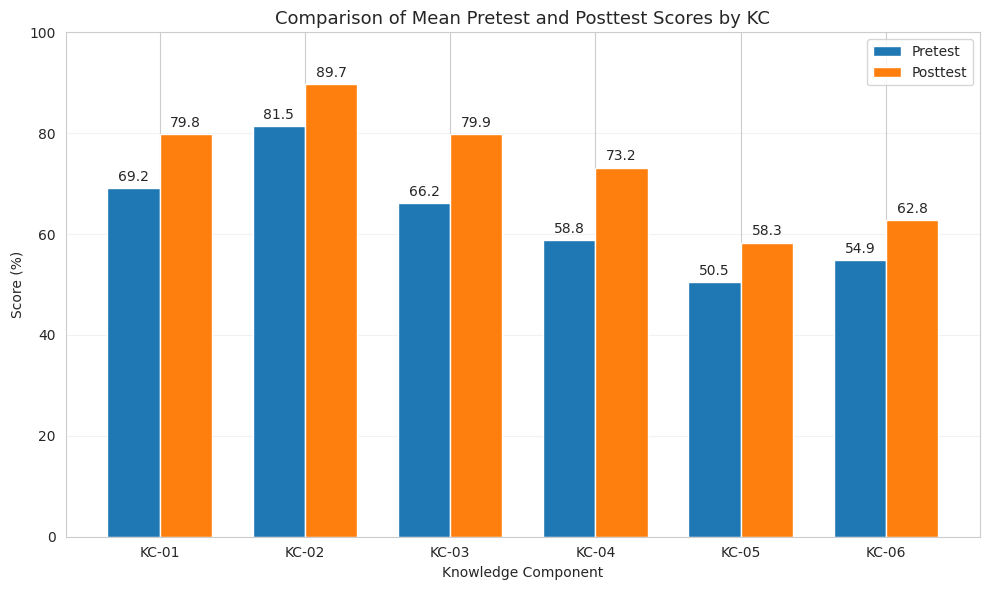

In [244]:
import numpy as np
import matplotlib.pyplot as plt

# Data
kcs = ['KC-01', 'KC-02', 'KC-03', 'KC-04', 'KC-05', 'KC-06']

pretest = [69.19, 81.46, 66.18, 58.82, 50.49, 54.90]
posttest = [79.83, 89.66, 79.90, 73.20, 58.33, 62.75]

# Bar positions
x = np.arange(len(kcs))
width = 0.36

# Plot
fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(
    x - width / 2,
    pretest,
    width,
    label='Pretest'
)

bars2 = ax.bar(
    x + width / 2,
    posttest,
    width,
    label='Posttest'
)

ax.set_title(
    'Comparison of Mean Pretest and Posttest Scores by KC',
    fontsize=13
)
ax.set_ylabel('Score (%)')
ax.set_xlabel('Knowledge Component')

ax.set_xticks(x)
ax.set_xticklabels(kcs)
ax.set_ylim(0, 100)

ax.legend()
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)

# Add value labels
ax.bar_label(bars1, fmt='%.1f', padding=3)
ax.bar_label(bars2, fmt='%.1f', padding=3)

plt.tight_layout()
plt.savefig(
    'grafik_pretest_posttest_per_kc.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

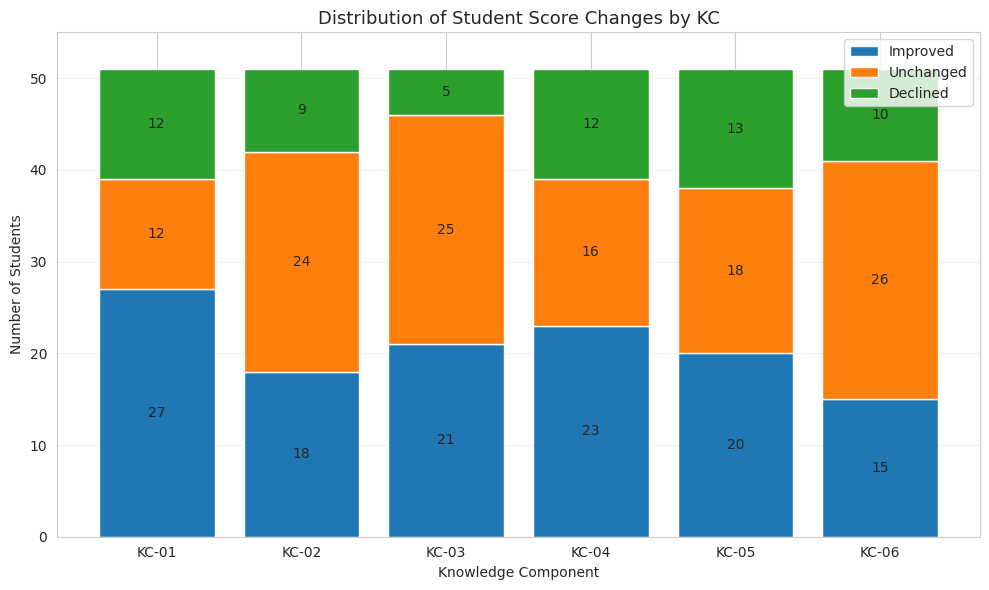

In [245]:
import matplotlib.pyplot as plt
import numpy as np

# Data
kcs = ['KC-01', 'KC-02', 'KC-03', 'KC-04', 'KC-05', 'KC-06']

increased = [27, 18, 21, 23, 20, 15]
unchanged = [12, 24, 25, 16, 18, 26]
decreased = [12, 9, 5, 12, 13, 10]

x = np.arange(len(kcs))

# Plot
fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(
    x,
    increased,
    label='Improved'
)

bars2 = ax.bar(
    x,
    unchanged,
    bottom=increased,
    label='Unchanged'
)

bottom_decreased = np.array(increased) + np.array(unchanged)

bars3 = ax.bar(
    x,
    decreased,
    bottom=bottom_decreased,
    label='Declined'
)

ax.set_title(
    'Distribution of Student Score Changes by KC',
    fontsize=13
)
ax.set_ylabel('Number of Students')
ax.set_xlabel('Knowledge Component')

ax.set_xticks(x)
ax.set_xticklabels(kcs)
ax.set_ylim(0, 55)

ax.legend()
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)

# Add student counts to each segment
for i in range(len(kcs)):
    ax.text(
        i,
        increased[i] / 2,
        str(increased[i]),
        ha='center',
        va='center'
    )

    ax.text(
        i,
        increased[i] + unchanged[i] / 2,
        str(unchanged[i]),
        ha='center',
        va='center'
    )

    ax.text(
        i,
        bottom_decreased[i] + decreased[i] / 2,
        str(decreased[i]),
        ha='center',
        va='center'
    )

plt.tight_layout()
plt.savefig(
    'grafik_distribusi_gain_per_kc.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

## 6. ALGORITHMIC RELIABILITY

### 6.1. SETUP AND CONFIG

In [260]:
# ============================================================
# SETUP
# ============================================================
!pip -q install scikit-learn scipy pandas numpy matplotlib seaborn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize
from scipy import stats
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, roc_curve
import warnings
warnings.filterwarnings("ignore")

# Set seed for reproducibility (REQUIRED for the thesis)
SEED = 42
np.random.seed(SEED)

# Path (adjust as needed)
BASE = '/content/drive/MyDrive/Skripsi-InkSkyCat/'

# BKT constants
KC_CONFIG = {
    "KC-01": {"pL0": 0.10, "pT": 0.15, "pS": 0.10, "pG": 0.30, "fluencyTarget": 3},
    "KC-02": {"pL0": 0.10, "pT": 0.15, "pS": 0.10, "pG": 0.30, "fluencyTarget": 3},
    "KC-03": {"pL0": 0.10, "pT": 0.10, "pS": 0.15, "pG": 0.15, "fluencyTarget": 3},
    "KC-04": {"pL0": 0.05, "pT": 0.08, "pS": 0.20, "pG": 0.10, "fluencyTarget": 3},
    "KC-05": {"pL0": 0.05, "pT": 0.05, "pS": 0.25, "pG": 0.05, "fluencyTarget": 4},
    "KC-06": {"pL0": 0.05, "pT": 0.05, "pS": 0.25, "pG": 0.05, "fluencyTarget": 4},
}
EXAM_PT = 0.05

# Reasonable BKT parameter ranges (for sanity checks)
PARAM_RANGES = {
    'pL0': (0.05, 0.40),
    'pT' : (0.01, 0.30),
    'pG' : (0.05, 0.30),
    'pS' : (0.05, 0.30),
}

print("✅ Setup completed")

✅ Setup completed


### 6.2. PREPROCESSING

In [261]:
# ============================================
# PREPARE: timestamp, drop leakage, check is_invalid
# ============================================
def prepare_bkt_df(d, name=''):
    d = d.copy()

    # --- 1. Create numeric timestamp ---
    # if 'timestamp' not in d.columns:
    #     if 'timestamp._seconds' in d.columns:
    #         nano = d['timestamp._nanoseconds'] if 'timestamp._nanoseconds' in d.columns else 0
    #         d['timestamp'] = d['timestamp._seconds'] + nano / 1e9
    #     else:
    #         raise KeyError(f"{name}: timestamp.* column not found")
    # print(f"  {name}: timestamp ✅ (range {d['timestamp'].min():.0f}–{d['timestamp'].max():.0f})")

    # --- 2. Drop leakage columns from production BKT ---
    leak = [c for c in ['pLBefore', 'pLAfter'] if c in d.columns]
    if leak:
        d = d.drop(columns=leak)
        print(f"  {name}: dropped leakage columns {leak} ✅")

    # --- 3. Cast isCorrect to int ---
    d['isCorrect'] = d['isCorrect'].astype(int)

    # --- 4. Check is_invalid ---
    if 'is_invalid' in d.columns:
        n_before = len(d)
        # True/1 = invalid → REMOVE invalid rows
        invalid_mask = d['is_invalid'].astype(bool) if d['is_invalid'].dtype != object \
                       else d['is_invalid'].astype(str).str.lower().isin(['true','1','yes'])
        d = d[~invalid_mask].copy()
        print(f"  {name}: filter is_invalid==False: {n_before} → {len(d)} "
              f"(removed {n_before - len(d)})")
    else:
        print(f"  {name}: column 'is_invalid' not found → skip filter")

    return d.reset_index(drop=True)


print("="*64)
print("PREPARE DATAFRAMES FOR BKT")
print("="*64)
df_practice = prepare_bkt_df(df_practice, 'practice')
df_pretest  = prepare_bkt_df(df_pretest,  'pretest')
df_posttest = prepare_bkt_df(df_posttest, 'posttest')
df_exam     = prepare_bkt_df(df_exam,     'exam')

print("\n" + "="*64)
print("AFTER PREPARATION")
print("="*64)
for name, d in [('practice', df_practice), ('pretest', df_pretest),
                ('posttest', df_posttest), ('exam', df_exam)]:
    print(f"{name:10s}: {len(d):>5} rows | "
          f"{d['userId'].nunique():>3} users | "
          f"remaining leakage columns: "
          f"{[c for c in ['pLBefore','pLAfter'] if c in d.columns] or 'none'}")

PREPARE DATAFRAMES FOR BKT
  practice: filter is_invalid==False: 5119 → 5119 (removed 0)
  pretest: filter is_invalid==False: 1581 → 1581 (removed 0)
  posttest: filter is_invalid==False: 1581 → 1581 (removed 0)
  exam: filter is_invalid==False: 3162 → 3162 (removed 0)

AFTER PREPARATION
practice  :  5119 rows |  51 users | remaining leakage columns: none
pretest   :  1581 rows |  51 users | remaining leakage columns: none
posttest  :  1581 rows |  51 users | remaining leakage columns: none
exam      :  3162 rows |  51 users | remaining leakage columns: none


In [262]:
# ============================================
# Detect KC column
# ============================================
KC_COL = None
for candidate in ['kcId', 'nodeId']:
    if candidate in df_practice.columns:
        vals = set(df_practice[candidate].astype(str).str.upper())
        match = vals & set(KC_CONFIG.keys())
        print(f"{candidate}: unique values={len(vals)}, KC_CONFIG matches={len(match)}")
        if match and KC_COL is None:
            KC_COL = candidate

if KC_COL is None:
    raise ValueError("No kcId/nodeId column matches KC_CONFIG. "
                     "Check unique values and KC_CONFIG keys.")

print(f"\n✅ Using KC column: '{KC_COL}'")
print(f"   Unique KCs in data: {sorted(df_practice[KC_COL].astype(str).str.upper().unique())}")
print(f"   KC_CONFIG keys    : {sorted(KC_CONFIG.keys())}")

kcId: unique values=6, KC_CONFIG matches=6
nodeId: unique values=16, KC_CONFIG matches=0

✅ Using KC column: 'kcId'
   Unique KCs in data: ['KC-01', 'KC-02', 'KC-03', 'KC-04', 'KC-05', 'KC-06']
   KC_CONFIG keys    : ['KC-01', 'KC-02', 'KC-03', 'KC-04', 'KC-05', 'KC-06']


In [263]:
# ============================================
# BUILD SEQUENCES
# ============================================
def build_sequences(d, kc_col, time_col='timestamp', min_len=2):
    required = ['userId', 'isCorrect', kc_col, time_col]
    missing = [c for c in required if c not in d.columns]
    if missing:
        raise KeyError(f"Missing columns: {missing}. Available: {d.columns.tolist()}")

    d = d.sort_values(['userId', kc_col, time_col]).copy()
    out = (d.groupby(['userId', kc_col])['isCorrect']
             .apply(lambda x: x.astype(int).tolist())
             .reset_index()
             .rename(columns={kc_col: 'kcId', 'isCorrect': 'seq'}))
    out['kcId'] = out['kcId'].astype(str).str.upper()
    out['len'] = out['seq'].apply(len)
    out = out[out['len'] >= min_len].reset_index(drop=True)

    print(f"  build_sequences: {len(out)} sequences | "
          f"median length={out['len'].median():.0f} | "
          f"users={out['userId'].nunique()} | "
          f"KCs={sorted(out['kcId'].unique())}")
    return out

print("="*64); print("SEQUENCE BUILDING"); print("="*64)
seqs_practice = build_sequences(df_practice, KC_COL)
seqs_pretest  = build_sequences(df_pretest,  KC_COL)
seqs_posttest = build_sequences(df_posttest, KC_COL)
seqs_exam     = build_sequences(df_exam,     KC_COL)

SEQUENCE BUILDING
  build_sequences: 264 sequences | median length=20 | users=51 | KCs=['KC-01', 'KC-02', 'KC-03', 'KC-04', 'KC-05', 'KC-06']
  build_sequences: 306 sequences | median length=4 | users=51 | KCs=['KC-01', 'KC-02', 'KC-03', 'KC-04', 'KC-05', 'KC-06']
  build_sequences: 306 sequences | median length=4 | users=51 | KCs=['KC-01', 'KC-02', 'KC-03', 'KC-04', 'KC-05', 'KC-06']
  build_sequences: 306 sequences | median length=8 | users=51 | KCs=['KC-01', 'KC-02', 'KC-03', 'KC-04', 'KC-05', 'KC-06']


In [264]:
for name, s in [('practice', seqs_practice), ('pretest', seqs_pretest), ('posttest', seqs_posttest)]:
    allobs = np.concatenate(s['seq'].tolist())
    print(f"{name}: n_obs={len(allobs)}, "
          f"correct_rate={allobs.mean():.3f}, "
          f"n_mixed_seq={s['seq'].apply(lambda x: 0 < sum(x) < len(x)).sum()}/{len(s)}")

practice: n_obs=5115, correct_rate=0.793, n_mixed_seq=199/264
pretest: n_obs=1581, correct_rate=0.688, n_mixed_seq=167/306
posttest: n_obs=1581, correct_rate=0.788, n_mixed_seq=159/306


### 6.3. JOINT SEQUENTIAL BKT

JOINT SEQUENTIAL BKT EXPERIMENT: MODEL TRAINING AND EVALUATION
Common students: 51
Knowledge components: 6
Fixed guessing probability: 0.25

OUTER FOLD 1/5
Inner-selected ensemble weights:
  pretest: BKT weight=0.78
  practice: BKT weight=0.62
  posttest: BKT weight=0.41

PRETEST
BKT                      ROC=0.7687 PR=0.8185
Persistence              ROC=0.6868 PR=0.6967
Running Accuracy         ROC=0.7340 PR=0.7431
BKT-Ensemble             ROC=0.7706 PR=0.8272

PRACTICE
BKT                      ROC=0.7624 PR=0.8943
Persistence              ROC=0.6344 PR=0.7880
Running Accuracy         ROC=0.7705 PR=0.8987
BKT-Ensemble             ROC=0.7779 PR=0.9074

POSTTEST
BKT                      ROC=0.7155 PR=0.8440
Persistence              ROC=0.6308 PR=0.7717
Running Accuracy         ROC=0.6886 PR=0.8279
BKT-Ensemble             ROC=0.7048 PR=0.8455

OUTER FOLD 2/5
Inner-selected ensemble weights:
  pretest: BKT weight=0.80
  practice: BKT weight=0.60
  posttest: BKT weight=0.28

PRETEST
BKT   

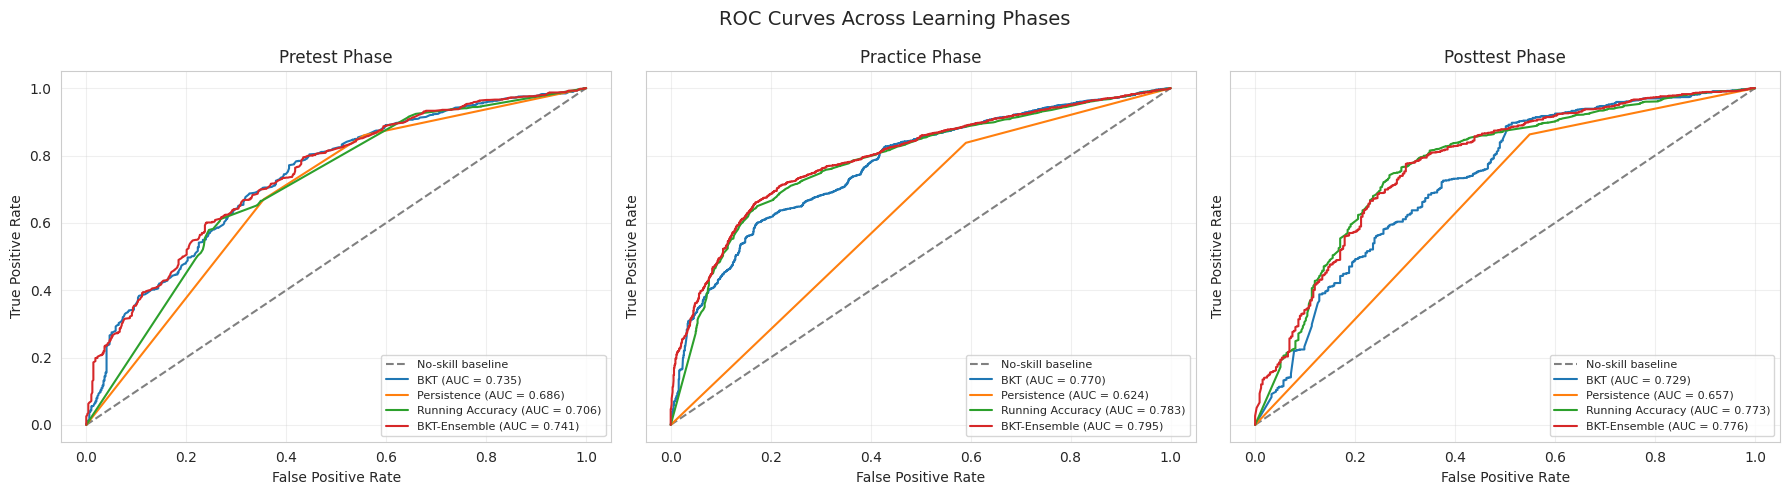

ROC curve diagram saved as: BKT_Joint_ROC_Curves.png

PAIRED WILCOXON TESTS WITH HOLM-ADJUSTED P-VALUES
Table guide: p_raw is the unadjusted p-value; p_Holm is the multiple-comparison-adjusted p-value; Significant indicates p_Holm < 0.05.
 Metric    Phase              Comparison  Statistic  p_raw  p_Holm  Significant
ROC-AUC  pretest      BKT vs Persistence     0.0000 0.0625  0.5625        False
ROC-AUC  pretest BKT vs Running Accuracy     0.0000 0.0625  0.5625        False
ROC-AUC  pretest     BKT-Ensemble vs BKT     4.0000 0.4375  0.9375        False
ROC-AUC practice      BKT vs Persistence     0.0000 0.0625  0.5625        False
ROC-AUC practice BKT vs Running Accuracy     6.0000 0.8125  0.9375        False
ROC-AUC practice     BKT-Ensemble vs BKT     1.0000 0.1250  0.6250        False
ROC-AUC posttest      BKT vs Persistence     0.0000 0.0625  0.5625        False
ROC-AUC posttest BKT vs Running Accuracy     3.0000 0.3125  0.9375        False
ROC-AUC posttest     BKT-Ensemble vs BKT 

In [266]:

# ================================================================
# FINAL JOINT SEQUENTIAL BKT EXPERIMENT
# ================================================================
# A. Joint fitting: pL0, pT, pS; pG fixed = 0.25
# B. Nested 5-fold GroupKFold: pretest -> practice -> posttest
# C. BKT vs Persistence vs Running Accuracy vs Ensemble
# D. ROC-AUC, PR-AUC, 95% cluster bootstrap CI,
#    Wilcoxon signed-rank + Holm correction
# E. Automatic deployment selection: BKT or Ensemble
#
# DATA REQUIREMENTS:
# seqs_pretest, seqs_practice, seqs_posttest
# Columns: userId, kcId, seq
# seq: ordered list/array of binary responses (0/1)
# ================================================================

import numpy as np
import pandas as pd

from scipy.optimize import minimize
from scipy import stats

from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve
)
import matplotlib.pyplot as plt


# ================================================================
# 1. CONFIGURATION
# ================================================================

JOINT_SEED = 42
OUTER_FOLDS = 5
INNER_FOLDS = 4

N_RESTARTS = 10
N_BOOTSTRAP = 2000

PG_FIXED = 0.25

PG_MC4 = 0.25                     # fixed guess for 4 options
PRETEST_PL0 = {'KC-01':0.30,'KC-02':0.30,'KC-03':0.30,'KC-04':0.30,
               'KC-05':0.20,'KC-06':0.20}

# Joint parameter bounds
JOINT_BOUNDS = [
    (0.01, 0.99),   # pL0
    (0.005, 0.25),  # pT
    (0.05, 0.30)    # pS
]

KC_LIST = sorted(PRETEST_PL0.keys())

PHASES = [
    "pretest",
    "practice",
    "posttest"
]

METHODS = [
    "BKT",
    "Persistence",
    "Running Accuracy",
    "BKT-Ensemble"
]

PHASE_DATA = {
    "pretest": seqs_pretest,
    "practice": seqs_practice,
    "posttest": seqs_posttest
}


# ================================================================
# 2. PREPARE SEQUENCE LOOKUP
# ================================================================

def build_sequence_lookup(df):

    lookup = {}

    for (user, kc), group in df.groupby(
        ["userId", "kcId"],
        sort=False
    ):

        sequences = []

        for seq in group["seq"]:

            arr = np.asarray(seq, dtype=int)

            if len(arr) > 0:
                if not np.isin(arr, [0, 1]).all():
                    raise ValueError(
                        f"Non-binary response found: {user}, {kc}"
                    )

                sequences.append(arr)

        if sequences:
            lookup[(user, kc)] = np.concatenate(sequences)

    return lookup


PHASE_LOOKUPS = {
    phase: build_sequence_lookup(df)
    for phase, df in PHASE_DATA.items()
}


def get_sequence(user, kc, lookup):

    return lookup.get(
        (user, kc),
        np.asarray([], dtype=int)
    )


# Use common users to ensure all three phases are represented.
COMMON_USERS = (
    set(seqs_pretest["userId"])
    & set(seqs_practice["userId"])
    & set(seqs_posttest["userId"])
)

ALL_USERS = np.asarray(sorted(COMMON_USERS))

if len(ALL_USERS) < OUTER_FOLDS:
    raise ValueError(
        f"Insufficient common users: {len(ALL_USERS)}"
    )

print("=" * 75)
print("JOINT SEQUENTIAL BKT EXPERIMENT: MODEL TRAINING AND EVALUATION")
print("=" * 75)

print("Common students:", len(ALL_USERS))
print("Knowledge components:", len(KC_LIST))
print("Fixed guessing probability:", PG_FIXED)


# ================================================================
# 3. JOINT BKT NEGATIVE LOG-LIKELIHOOD
# ================================================================

def joint_bkt_nll(theta, sequences):

    pL0, pT, pS = theta

    total_nll = 0.0

    for seq in sequences:

        pL = float(pL0)

        for obs in seq:

            # Probability of correct response
            p_correct = (
                pL * (1 - pS)
                + (1 - pL) * PG_FIXED
            )

            p_correct = np.clip(
                p_correct, 1e-9, 1 - 1e-9
            )

            # Observation likelihood
            if obs == 1:
                total_nll -= np.log(p_correct)
                pL = pL * (1 - pS) / p_correct

            else:
                total_nll -= np.log(1 - p_correct)
                pL = pL * pS / (1 - p_correct)

            # Learning transition after each opportunity
            pL = pL + (1 - pL) * pT

    return total_nll


# ================================================================
# 4. JOINT PARAMETER FITTING PER KC
# ================================================================

def fit_joint_parameters(training_users):

    training_users = set(training_users)

    parameters = {}

    for kc in KC_LIST:

        sequences = []

        for user in training_users:

            phase_sequences = []

            for phase in PHASES:

                seq = get_sequence(
                    user,
                    kc,
                    PHASE_LOOKUPS[phase]
                )

                if len(seq):
                    phase_sequences.append(seq)

            if phase_sequences:

                # Preserve temporal order:
                # pretest -> practice -> posttest
                combined = np.concatenate(
                    phase_sequences
                )

                sequences.append(combined)

        if len(sequences) < 2:
            raise ValueError(
                f"Insufficient sequences for {kc}"
            )

        best_result = None

        # Deterministic initialization plus random restarts
        rng = np.random.default_rng(
            JOINT_SEED + KC_LIST.index(kc)
            + len(training_users)
        )

        initial_points = [
            np.array([0.30, 0.10, 0.15]),
            np.array([0.50, 0.10, 0.15]),
            np.array([0.70, 0.10, 0.15])
        ]

        for _ in range(N_RESTARTS):
            initial_points.append(
                np.array([
                    rng.uniform(0.05, 0.95),
                    rng.uniform(0.005, 0.25),
                    rng.uniform(0.05, 0.30)
                ])
            )

        for x0 in initial_points:

            result = minimize(
                joint_bkt_nll,
                x0,
                args=(sequences,),
                method="L-BFGS-B",
                bounds=JOINT_BOUNDS,
                options={
                    "maxiter": 1000,
                    "ftol": 1e-10
                }
            )

            if (
                result.success
                and np.isfinite(result.fun)
                and (
                    best_result is None
                    or result.fun < best_result.fun
                )
            ):
                best_result = result

        if best_result is None:
            raise RuntimeError(
                f"Joint fitting failed for {kc}"
            )

        pL0, pT, pS = best_result.x

        parameters[kc] = {
            "pL0": float(pL0),
            "pT": float(pT),
            "pG": PG_FIXED,
            "pS": float(pS),
            "NLL": float(best_result.fun)
        }

    return parameters


# ================================================================
# 5. SEQUENTIAL BKT PREDICTION
# ================================================================

def sequential_bkt_predict(seq, state, pT, pS):

    predictions = []

    pL = float(state)

    for obs in seq:

        p_correct = (
            pL * (1 - pS)
            + (1 - pL) * PG_FIXED
        )

        p_correct = np.clip(
            p_correct, 1e-9, 1 - 1e-9
        )

        predictions.append(p_correct)

        # Bayesian knowledge update
        if obs == 1:

            pL = (
                pL * (1 - pS)
                / p_correct
            )

        else:

            pL = (
                pL * pS
                / (1 - p_correct)
            )

        # Learning transition before next opportunity
        pL = pL + (1 - pL) * pT

    return np.asarray(predictions), float(pL)


# ================================================================
# 6. SEQUENTIAL BASELINE PREDICTIONS
# ================================================================

def sequential_baselines(seq, history):

    persistence = []
    running_accuracy = []

    past = list(history)

    for obs in seq:

        if past:
            persistence.append(float(past[-1]))
            running_accuracy.append(float(np.mean(past)))

        else:
            persistence.append(0.5)
            running_accuracy.append(0.5)

        past.append(int(obs))

    return (
        np.asarray(persistence),
        np.asarray(running_accuracy)
    )


# ================================================================
# 7. PREDICT ALL PHASES FOR SELECTED USERS
# ================================================================

def predict_sequential_users(parameters, selected_users):

    selected_users = set(selected_users)

    records = []

    for user in selected_users:

        for kc in KC_LIST:

            if kc not in parameters:
                continue

            p = parameters[kc]

            state = p["pL0"]

            history = []

            for phase in PHASES:

                seq = get_sequence(
                    user,
                    kc,
                    PHASE_LOOKUPS[phase]
                )

                if len(seq) == 0:
                    continue

                # BKT prediction and posterior update
                bkt_pred, state = sequential_bkt_predict(
                    seq,
                    state,
                    p["pT"],
                    p["pS"]
                )

                # Sequential baselines also carry prior-phase history
                pers_pred, acc_pred = sequential_baselines(
                    seq,
                    history
                )

                for i, obs in enumerate(seq):

                    records.append({
                        "userId": user,
                        "KC": kc,
                        "Phase": phase,
                        "Step": i,
                        "Actual": int(obs),
                        "BKT": float(bkt_pred[i]),
                        "Persistence": float(pers_pred[i]),
                        "Running Accuracy": float(acc_pred[i])
                    })

                history.extend(seq.tolist())

    return pd.DataFrame(records)


# ================================================================
# 8. METRICS
# ================================================================

def calculate_metrics(df, prediction_column):

    if len(df) == 0:
        return np.nan, np.nan

    y = df["Actual"].to_numpy()
    pred = df[prediction_column].to_numpy()

    if len(np.unique(y)) < 2:
        return np.nan, np.nan

    return (
        roc_auc_score(y, pred),
        average_precision_score(y, pred)
    )


def add_ensemble_predictions(df, weights):

    result = df.copy()

    result["BKT-Ensemble"] = np.nan

    for phase in PHASES:

        mask = result["Phase"] == phase

        w = weights[phase]

        result.loc[mask, "BKT-Ensemble"] = (
            w * result.loc[mask, "BKT"]
            + (1 - w)
            * result.loc[mask, "Running Accuracy"]
        )

    return result


# ================================================================
# 9. INNER OOF PREDICTIONS FOR ENSEMBLE WEIGHT SELECTION
# ================================================================

def generate_inner_oof(training_users, n_splits=INNER_FOLDS):

    training_users = np.asarray(
        sorted(training_users)
    )

    if len(training_users) < n_splits:
        raise ValueError(
            "Insufficient users for inner cross-validation."
        )

    gkf = GroupKFold(n_splits=n_splits)

    inner_records = []

    for inner_fold, (tr, va) in enumerate(
        gkf.split(
            training_users,
            groups=training_users
        )
    ):

        inner_train_users = set(
            training_users[tr]
        )

        inner_valid_users = set(
            training_users[va]
        )

        inner_params = fit_joint_parameters(
            inner_train_users
        )

        predictions = predict_sequential_users(
            inner_params,
            inner_valid_users
        )

        predictions["InnerFold"] = inner_fold + 1

        inner_records.append(predictions)

    return pd.concat(
        inner_records,
        ignore_index=True
    )


# ================================================================
# 10. SELECT ENSEMBLE WEIGHT USING INNER OOF
# ================================================================

def select_ensemble_weights(inner_oof):

    weights = {}

    weight_grid = np.linspace(
        0.0, 1.0, 101
    )

    for phase in PHASES:

        subset = inner_oof[
            inner_oof["Phase"] == phase
        ]

        best_weight = 1.0
        best_score = -np.inf

        for w in weight_grid:

            prediction = (
                w * subset["BKT"].to_numpy()
                + (1 - w)
                * subset["Running Accuracy"].to_numpy()
            )

            y = subset["Actual"].to_numpy()

            if len(np.unique(y)) < 2:
                continue

            score = roc_auc_score(
                y,
                prediction
            )

            if score > best_score:

                best_score = score
                best_weight = float(w)

        weights[phase] = best_weight

    return weights


# ================================================================
# 11. OUTER NESTED FIVE-FOLD CV
# ================================================================

def run_nested_joint_cv():

    outer = GroupKFold(
        n_splits=OUTER_FOLDS
    )

    fold_results = []
    outer_oof = []
    weight_results = []
    parameter_results = []

    for fold, (tr, te) in enumerate(
        outer.split(
            ALL_USERS,
            groups=ALL_USERS
        )
    ):

        train_users = set(ALL_USERS[tr])
        test_users = set(ALL_USERS[te])

        print("\n" + "=" * 75)
        print(f"OUTER FOLD {fold + 1}/{OUTER_FOLDS}")
        print("=" * 75)

        # --------------------------------------------------------
        # INNER CV: select ensemble weights using training users
        # --------------------------------------------------------

        inner_oof = generate_inner_oof(
            train_users,
            INNER_FOLDS
        )

        weights = select_ensemble_weights(
            inner_oof
        )

        print("Inner-selected ensemble weights:")

        for phase, w in weights.items():
            print(f"  {phase}: BKT weight={w:.2f}")

        # --------------------------------------------------------
        # FIT FINAL JOINT BKT ON OUTER TRAINING USERS
        # --------------------------------------------------------

        outer_params = fit_joint_parameters(
            train_users
        )

        for kc, p in outer_params.items():

            parameter_results.append({
                "Fold": fold + 1,
                "KC": kc,
                **p
            })

        # --------------------------------------------------------
        # PREDICT OUTER TEST USERS
        # --------------------------------------------------------

        predictions = predict_sequential_users(
            outer_params,
            test_users
        )

        predictions = add_ensemble_predictions(
            predictions,
            weights
        )

        predictions["OuterFold"] = fold + 1

        outer_oof.append(predictions)

        weight_results.append({
            "Fold": fold + 1,
            **{
                f"Weight_{phase}": w
                for phase, w in weights.items()
            }
        })

        # --------------------------------------------------------
        # EVALUATE ALL METHODS
        # --------------------------------------------------------

        for phase in PHASES:

            phase_df = predictions[
                predictions["Phase"] == phase
            ]

            print(f"\n{phase.upper()}")

            for method in METHODS:

                roc, pr = calculate_metrics(
                    phase_df,
                    method
                )

                fold_results.append({
                    "Fold": fold + 1,
                    "Phase": phase,
                    "Method": method,
                    "ROC-AUC": roc,
                    "PR-AUC": pr
                })

                print(
                    f"{method:24s} "
                    f"ROC={roc:.4f} "
                    f"PR={pr:.4f}"
                )

    return (
        pd.DataFrame(fold_results),
        pd.concat(outer_oof, ignore_index=True),
        pd.DataFrame(weight_results),
        pd.DataFrame(parameter_results)
    )


# ================================================================
# 12. EXECUTE NESTED CV
# ================================================================

np.random.seed(JOINT_SEED)

fold_df, oof_df, weights_df, fold_params_df = (
    run_nested_joint_cv()
)


# ================================================================
# 13. SUMMARY: MEAN ± SD
# ================================================================

summary_df = (
    fold_df.groupby(["Phase", "Method"])
    .agg(
        ROC_mean=("ROC-AUC", "mean"),
        ROC_sd=("ROC-AUC", "std"),
        PR_mean=("PR-AUC", "mean"),
        PR_sd=("PR-AUC", "std")
    )
    .reset_index()
)

print("\n" + "=" * 90)
print("NESTED 5-FOLD CROSS-VALIDATION RESULTS: MEAN ± STANDARD DEVIATION")
print("=" * 90)

for phase in PHASES:

    print(f"\n{phase.upper()}")

    subset = summary_df[
        summary_df["Phase"] == phase
    ]

    for _, r in subset.iterrows():

        print(
            f"{r['Method']:24s} "
            f"ROC={r['ROC_mean']:.4f} ± {r['ROC_sd']:.4f} "
            f"PR={r['PR_mean']:.4f} ± {r['PR_sd']:.4f}"
        )




# ================================================================
# 14. ROC CURVE VISUALIZATION
# ================================================================

# Plot ROC curves from outer-fold out-of-fold predictions.
# Each panel represents one phase; each curve represents one method.
fig, axes = plt.subplots(1, len(PHASES), figsize=(18, 5), sharex=True, sharey=True)

for ax, phase in zip(axes, PHASES):
    phase_df = oof_df[oof_df["Phase"] == phase]
    y_true = phase_df["Actual"].to_numpy()

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="gray",
        label="No-skill baseline"
    )

    if len(np.unique(y_true)) < 2:
        ax.set_title(f"{phase.title()} (ROC unavailable)")
        ax.text(
            0.5, 0.5,
            "ROC curve requires both classes",
            ha="center",
            va="center",
            transform=ax.transAxes
        )
    else:
        for method in METHODS:
            y_score = phase_df[method].to_numpy()
            valid = np.isfinite(y_score)

            if valid.sum() == 0 or len(np.unique(y_true[valid])) < 2:
                continue

            fpr, tpr, _ = roc_curve(y_true[valid], y_score[valid])
            auc_value = roc_auc_score(y_true[valid], y_score[valid])

            ax.plot(
                fpr,
                tpr,
                label=f"{method} (AUC = {auc_value:.3f})"
            )

        ax.set_title(f"{phase.title()} Phase")

    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.grid(alpha=0.3)
    ax.legend(loc="lower right", fontsize=8)

fig.suptitle("ROC Curves Across Learning Phases", fontsize=14)
fig.tight_layout()
fig.savefig("BKT_Joint_ROC_Curves.png", dpi=300, bbox_inches="tight")
plt.show()

print("ROC curve diagram saved as: BKT_Joint_ROC_Curves.png")

# ================================================================
# 15. WILCOXON PAIRED BY OUTER FOLD
# ================================================================

def holm_adjust(p_values):

    p_values = np.asarray(p_values, dtype=float)

    m = len(p_values)

    order = np.argsort(p_values)

    adjusted = np.empty(m)

    running_max = 0.0

    for rank, idx in enumerate(order):

        value = min(
            1.0,
            (m - rank) * p_values[idx]
        )

        running_max = max(
            running_max,
            value
        )

        adjusted[idx] = running_max

    return adjusted


print("\n" + "=" * 90)
print("PAIRED WILCOXON TESTS WITH HOLM-ADJUSTED P-VALUES")
print("=" * 90)

comparison_pairs = [
    ("BKT", "Persistence"),
    ("BKT", "Running Accuracy"),
    ("BKT-Ensemble", "BKT")
]

wilcoxon_rows = []

for metric in ["ROC-AUC", "PR-AUC"]:

    for phase in PHASES:

        for method_a, method_b in comparison_pairs:

            a = (
                fold_df[
                    (fold_df["Phase"] == phase)
                    & (fold_df["Method"] == method_a)
                ]
                .sort_values("Fold")[metric]
                .to_numpy()
            )

            b = (
                fold_df[
                    (fold_df["Phase"] == phase)
                    & (fold_df["Method"] == method_b)
                ]
                .sort_values("Fold")[metric]
                .to_numpy()
            )

            valid = np.isfinite(a) & np.isfinite(b)

            if valid.sum() < 2:
                continue

            if np.allclose(a[valid] - b[valid], 0):
                statistic, p_value = 0.0, 1.0

            else:

                statistic, p_value = stats.wilcoxon(
                    a[valid],
                    b[valid],
                    alternative="two-sided",
                    method="exact"
                )

            wilcoxon_rows.append({
                "Metric": metric,
                "Phase": phase,
                "Comparison": f"{method_a} vs {method_b}",
                "Statistic": statistic,
                "p_raw": p_value
            })

wilcoxon_df = pd.DataFrame(wilcoxon_rows)

# Holm correction separately for ROC and PR families
wilcoxon_df["p_Holm"] = np.nan

for metric in ["ROC-AUC", "PR-AUC"]:

    mask = wilcoxon_df["Metric"] == metric

    wilcoxon_df.loc[mask, "p_Holm"] = holm_adjust(
        wilcoxon_df.loc[mask, "p_raw"].to_numpy()
    )

wilcoxon_df["Significant"] = (
    wilcoxon_df["p_Holm"] < 0.05
)

print("Table guide: p_raw is the unadjusted p-value; p_Holm is the multiple-comparison-adjusted p-value; Significant indicates p_Holm < 0.05.")
print(
    wilcoxon_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ================================================================
# 16. USER-LEVEL CLUSTER BOOTSTRAP 95% CI
# ================================================================

def bootstrap_metric_ci(
    df,
    method,
    n_boot=N_BOOTSTRAP,
    seed=JOINT_SEED
):

    rng = np.random.default_rng(seed)

    users = df["userId"].unique()

    groups = {
        user: df[df["userId"] == user]
        for user in users
    }

    roc_values = []
    pr_values = []

    for _ in range(n_boot):

        sampled_users = rng.choice(
            users,
            size=len(users),
            replace=True
        )

        sample = pd.concat(
            [groups[u] for u in sampled_users],
            ignore_index=True
        )

        if sample["Actual"].nunique() < 2:
            continue

        roc, pr = calculate_metrics(
            sample,
            method
        )

        if np.isfinite(roc) and np.isfinite(pr):

            roc_values.append(roc)
            pr_values.append(pr)

    if len(roc_values) < 100:
        raise RuntimeError(
            "Insufficient valid bootstrap samples."
        )

    return {
        "ROC_low": np.percentile(roc_values, 2.5),
        "ROC_high": np.percentile(roc_values, 97.5),
        "PR_low": np.percentile(pr_values, 2.5),
        "PR_high": np.percentile(pr_values, 97.5),
        "Valid_bootstrap": len(roc_values)
    }


print("\n" + "=" * 90)
print("95% CONFIDENCE INTERVALS FROM USER-LEVEL CLUSTER BOOTSTRAPPING")
print("Table guide: ROC_low/ROC_high and PR_low/PR_high are the 2.5th and 97.5th percentiles of valid user-cluster bootstrap estimates.")
print("=" * 90)

ci_rows = []

for phase in PHASES:

    phase_df = oof_df[
        oof_df["Phase"] == phase
    ]

    for method in METHODS:

        ci = bootstrap_metric_ci(
            phase_df,
            method
        )

        ci_rows.append({
            "Phase": phase,
            "Method": method,
            **ci
        })

        print(
            f"{phase:10s} {method:24s} "
            f"ROC=[{ci['ROC_low']:.4f}, {ci['ROC_high']:.4f}] "
            f"PR=[{ci['PR_low']:.4f}, {ci['PR_high']:.4f}]"
        )

ci_df = pd.DataFrame(ci_rows)


# ================================================================
# 17. PAIRED BOOTSTRAP DIFFERENCE: ENSEMBLE - BKT
# ================================================================

def bootstrap_paired_difference(
    df,
    method_a,
    method_b,
    n_boot=N_BOOTSTRAP,
    seed=JOINT_SEED
):

    rng = np.random.default_rng(seed)

    users = df["userId"].unique()

    groups = {
        user: df[df["userId"] == user]
        for user in users
    }

    roc_differences = []
    pr_differences = []

    for _ in range(n_boot):

        sampled_users = rng.choice(
            users,
            size=len(users),
            replace=True
        )

        sample = pd.concat(
            [groups[u] for u in sampled_users],
            ignore_index=True
        )

        if sample["Actual"].nunique() < 2:
            continue

        roc_a, pr_a = calculate_metrics(
            sample, method_a
        )

        roc_b, pr_b = calculate_metrics(
            sample, method_b
        )

        if np.all(
            np.isfinite([roc_a, pr_a, roc_b, pr_b])
        ):

            roc_differences.append(roc_a - roc_b)
            pr_differences.append(pr_a - pr_b)

    return {
        "ROC_diff_mean": np.mean(roc_differences),
        "ROC_diff_low": np.percentile(roc_differences, 2.5),
        "ROC_diff_high": np.percentile(roc_differences, 97.5),
        "PR_diff_mean": np.mean(pr_differences),
        "PR_diff_low": np.percentile(pr_differences, 2.5),
        "PR_diff_high": np.percentile(pr_differences, 97.5)
    }


practice_oof = oof_df[
    oof_df["Phase"] == "practice"
]

practice_difference = bootstrap_paired_difference(
    practice_oof,
    "BKT-Ensemble",
    "BKT"
)

print("\n" + "=" * 90)
print("PRACTICE PHASE: PAIRED BOOTSTRAP PERFORMANCE DIFFERENCE (ENSEMBLE MINUS BKT)")
print("=" * 90)

print(
    "ROC difference: "
    f"{practice_difference['ROC_diff_mean']:.4f} "
    f"[{practice_difference['ROC_diff_low']:.4f}, "
    f"{practice_difference['ROC_diff_high']:.4f}]"
)

print(
    "PR difference: "
    f"{practice_difference['PR_diff_mean']:.4f} "
    f"[{practice_difference['PR_diff_low']:.4f}, "
    f"{practice_difference['PR_diff_high']:.4f}]"
)


# ================================================================
# 18. AUTOMATIC DEPLOYMENT MODEL SELECTION
# ================================================================

practice_summary = summary_df[
    summary_df["Phase"] == "practice"
].set_index("Method")

bkt_roc = practice_summary.loc["BKT", "ROC_mean"]
ens_roc = practice_summary.loc["BKT-Ensemble", "ROC_mean"]

bkt_pr = practice_summary.loc["BKT", "PR_mean"]
ens_pr = practice_summary.loc["BKT-Ensemble", "PR_mean"]

# Conservative selection:
# Ensemble only if paired 95% ROC difference is entirely positive
# and mean PR-AUC does not decrease.

ensemble_is_better = (
    practice_difference["ROC_diff_low"] > 0
    and ens_pr >= bkt_pr
)

DEPLOYMENT_MODEL = (
    "BKT-Ensemble"
    if ensemble_is_better
    else "BKT"
)

print("\n" + "=" * 90)
print("DEPLOYMENT MODEL SELECTION BASED ON PRACTICE-PHASE PERFORMANCE")
print("=" * 90)

print(f"Practice BKT ROC-AUC:      {bkt_roc:.4f}")
print(f"Practice Ensemble ROC-AUC: {ens_roc:.4f}")

print(f"Practice BKT PR-AUC:       {bkt_pr:.4f}")
print(f"Practice Ensemble PR-AUC:  {ens_pr:.4f}")

print("\nSelected deployment model:", DEPLOYMENT_MODEL)


# ================================================================
# 19. FINAL ENSEMBLE WEIGHTS USING ALL-USER OOF
# ================================================================

print("\n" + "=" * 90)
print("FINAL ENSEMBLE WEIGHTS ESTIMATED FROM ALL-USER OUT-OF-FOLD PREDICTIONS")
print("=" * 90)

full_oof = generate_inner_oof(
    set(ALL_USERS),
    n_splits=5
)

FINAL_WEIGHTS = select_ensemble_weights(
    full_oof
)

for phase, w in FINAL_WEIGHTS.items():

    print(
        f"{phase:10s}: "
        f"BKT={w:.2f}, "
        f"Running Accuracy={1-w:.2f}"
    )


# ================================================================
# 20. FINAL JOINT FIT ON ALL AVAILABLE STUDENTS
# ================================================================

print("\n" + "=" * 90)
print("FINAL JOINT BKT PARAMETER ESTIMATES FOR EACH KNOWLEDGE COMPONENT")
print("=" * 90)

FINAL_PARAMETERS = fit_joint_parameters(
    set(ALL_USERS)
)

final_parameter_rows = []

for kc in KC_LIST:

    p = FINAL_PARAMETERS[kc]

    final_parameter_rows.append({
        "KC": kc,
        "pL0": p["pL0"],
        "pT": p["pT"],
        "pG": p["pG"],
        "pS": p["pS"],
        "NLL": p["NLL"]
    })

final_parameters_df = pd.DataFrame(
    final_parameter_rows
)

print(
    final_parameters_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ================================================================
# 21. TYPESCRIPT EXPORT
# ================================================================

ts_lines = ["const KC_CONFIG = {"]

for kc in KC_LIST:

    p = FINAL_PARAMETERS[kc]

    ts_lines.append(
        f'  "{kc}": {{ '
        f'pL0: {p["pL0"]:.4f}, '
        f'pT: {p["pT"]:.4f}, '
        f'pS: {p["pS"]:.4f}, '
        f'pG: {p["pG"]:.2f} '
        f'}},'
    )

ts_lines.append("};")

typescript_config = "\n".join(ts_lines)

print("\n" + "=" * 90)
print("EXPORTED TYPESCRIPT CONFIGURATION FOR KNOWLEDGE COMPONENTS")
print("=" * 90)

print(typescript_config)


# ================================================================
# 22. SAVE RESULTS
# ================================================================

summary_df.to_csv(
    "BKT_Joint_Summary.csv",
    index=False
)

fold_df.to_csv(
    "BKT_Joint_Fold_Performance.csv",
    index=False
)

oof_df.to_csv(
    "BKT_Joint_OOF_Predictions.csv",
    index=False
)

wilcoxon_df.to_csv(
    "BKT_Joint_Wilcoxon_Holm.csv",
    index=False
)

ci_df.to_csv(
    "BKT_Joint_95CI.csv",
    index=False
)

weights_df.to_csv(
    "BKT_Joint_Outer_Weights.csv",
    index=False
)

fold_params_df.to_csv(
    "BKT_Joint_Fold_Parameters.csv",
    index=False
)

final_parameters_df.to_csv(
    "BKT_Joint_Final_Parameters.csv",
    index=False
)

pd.DataFrame([
    {
        "Phase": phase,
        "BKT_Weight": w,
        "Running_Accuracy_Weight": 1-w
    }
    for phase, w in FINAL_WEIGHTS.items()
]).to_csv(
    "BKT_Joint_Final_Ensemble_Weights.csv",
    index=False
)

pd.DataFrame([{
    "Deployment_Model": DEPLOYMENT_MODEL,
    "Practice_BKT_ROC": bkt_roc,
    "Practice_Ensemble_ROC": ens_roc,
    "Practice_BKT_PR": bkt_pr,
    "Practice_Ensemble_PR": ens_pr,
    **practice_difference
}]).to_csv(
    "BKT_Joint_Deployment_Decision.csv",
    index=False
)

with open(
    "BKT_Joint_Final_KC_CONFIG.ts",
    "w",
    encoding="utf-8"
) as f:

    f.write(typescript_config)

print("\n" + "=" * 90)
print("JOINT SEQUENTIAL BKT EXPERIMENT FINISHED SUCCESSFULLY")
print("=" * 90)

print("Deployment:", DEPLOYMENT_MODEL)

print("\nOutput files generated by this experiment:")
print("1. BKT_Joint_Summary.csv")
print("2. BKT_Joint_Fold_Performance.csv")
print("3. BKT_Joint_OOF_Predictions.csv")
print("4. BKT_Joint_Wilcoxon_Holm.csv")
print("5. BKT_Joint_95CI.csv")
print("6. BKT_Joint_Outer_Weights.csv")
print("7. BKT_Joint_Fold_Parameters.csv")
print("8. BKT_Joint_Final_Parameters.csv")
print("9. BKT_Joint_Final_Ensemble_Weights.csv")
print("10. BKT_Joint_Deployment_Decision.csv")
print("11. BKT_Joint_Final_KC_CONFIG.ts")
print("12. BKT_Joint_ROC_Curves.png")


In [267]:

import numpy as np
import pandas as pd
from scipy.stats import spearmanr

# ============================================================
# 1. FINAL JOINT BKT PARAMETERS
#    Latest parameters from Joint Sequential BKT
# ============================================================

FINAL_PARAMETERS = {
    "KC-01": {"pL0": 0.8110, "pT": 0.0299, "pG": 0.25, "pS": 0.2191},
    "KC-02": {"pL0": 0.7630, "pT": 0.0377, "pG": 0.25, "pS": 0.0520},
    "KC-03": {"pL0": 0.6732, "pT": 0.0391, "pG": 0.25, "pS": 0.1316},
    "KC-04": {"pL0": 0.4937, "pT": 0.0716, "pG": 0.25, "pS": 0.1711},
    "KC-05": {"pL0": 0.2673, "pT": 0.0242, "pG": 0.25, "pS": 0.1135},
    "KC-06": {"pL0": 0.4453, "pT": 0.1585, "pG": 0.25, "pS": 0.1097},
}

PHASE_DATA = {
    "pretest": seqs_pretest,
    "practice": seqs_practice,
    "posttest": seqs_posttest
}

KC_LIST = list(FINAL_PARAMETERS.keys())

SEED = 42
N_BOOTSTRAP = 2000


# ============================================================
# 2. PREPARE STUDENT-KC SEQUENCES
# ============================================================

def prepare_lookup(df):

    lookup = {}

    for (user, kc), group in df.groupby(
        ["userId", "kcId"], sort=False
    ):

        sequences = []

        for seq in group["seq"]:

            if seq is None:
                continue

            arr = np.asarray(seq, dtype=int)

            if len(arr) == 0:
                continue

            if not np.isin(arr, [0, 1]).all():
                raise ValueError(
                    f"Invalid binary response: {user}, {kc}"
                )

            sequences.append(arr)

        if sequences:
            lookup[(user, kc)] = np.concatenate(sequences)

    return lookup


LOOKUPS = {
    phase: prepare_lookup(df)
    for phase, df in PHASE_DATA.items()
}


# ============================================================
# 3. BKT UPDATE FUNCTION
# ============================================================

def bkt_update_sequence(sequence, pL, params):

    pT = params["pT"]
    pG = params["pG"]
    pS = params["pS"]

    for response in sequence:

        # Probability of a correct answer
        p_correct = (
            pL * (1 - pS)
            + (1 - pL) * pG
        )

        p_correct = np.clip(
            p_correct, 1e-10, 1 - 1e-10
        )

        # Bayesian knowledge update
        if response == 1:

            pL = (
                pL * (1 - pS)
                / p_correct
            )

        else:

            pL = (
                pL * pS
                / (1 - p_correct)
            )

        # Learning transition
        pL = pL + (1 - pL) * pT

    return float(pL)


# ============================================================
# 4. CALCULATE RAW POSTTEST ACCURACY
# ============================================================

def calculate_raw_accuracy(sequence):

    total = len(sequence)

    if total == 0:
        return None

    correct = int(np.sum(sequence))
    incorrect = total - correct

    return {
        "Correct": correct,
        "Incorrect": incorrect,
        "Total": total,
        "Accuracy": correct / total * 100
    }


# ============================================================
# 5. CALCULATE MASTERY PER STUDENT AND KC
# ============================================================

records = []

common_keys = (
    set(LOOKUPS["pretest"])
    & set(LOOKUPS["practice"])
    & set(LOOKUPS["posttest"])
)

for user, kc in sorted(
    common_keys,
    key=lambda x: (str(x[0]), str(x[1]))
):

    if kc not in FINAL_PARAMETERS:
        continue

    params = FINAL_PARAMETERS[kc]

    pre_seq = LOOKUPS["pretest"][(user, kc)]
    practice_seq = LOOKUPS["practice"][(user, kc)]
    post_seq = LOOKUPS["posttest"][(user, kc)]

    # Initial mastery
    pL = params["pL0"]

    # Process PRETEST
    pL = bkt_update_sequence(
        pre_seq, pL, params
    )

    # Process PRACTICE
    pL = bkt_update_sequence(
        practice_seq, pL, params
    )

    end_practice_mastery = pL

    # Process POSTTEST
    pL = bkt_update_sequence(
        post_seq, pL, params
    )

    end_posttest_mastery = pL

    # Pure posttest score, independent of BKT
    raw = calculate_raw_accuracy(post_seq)

    records.append({
        "Student": user,
        "KC": kc,

        "Practice_Mastery": end_practice_mastery * 100,

        "Posttest_Master y": end_posttest_mastery * 100,

        "Posttest_Correct": raw["Correct"],
        "Posttest_Incorrect": raw["Incorrect"],
        "Posttest_Total": raw["Total"],

        "Posttest_Accuracy": raw["Accuracy"],

        "Mastery_Change": (
            end_posttest_mastery
            - end_practice_mastery
        ) * 100
    })


# ============================================================
# 6. CLEAN DATA
# ============================================================

mastery_df = pd.DataFrame(records)

# Correct column name
mastery_df = mastery_df.rename(columns={
    "Posttest_Master y": "Posttest_Mastery"
})

if mastery_df.empty:
    raise ValueError("No matching student-KC observations.")

print("\nMatched observations:", len(mastery_df))
print("Unique students:", mastery_df["Student"].nunique())


# ============================================================
# 7. SPEARMAN CORRELATION
# ============================================================

def spearman_analysis(df, x, y):

    valid = df[[x, y]].dropna()

    if len(valid) < 3:
        return np.nan, np.nan, len(valid)

    rho, p = spearmanr(
        valid[x],
        valid[y]
    )

    return rho, p, len(valid)


print("\n" + "=" * 85)
print("BKT MASTERY VS POSTTEST LEARNING OUTCOMES")
print("=" * 85)


# MAIN ANALYSIS
rho_practice, p_practice, n_practice = (
    spearman_analysis(
        mastery_df,
        "Practice_Master y".replace(" ", ""),
        "Posttest_Accuracy"
    )
)

print("\n1. END-PRACTICE MASTERY vs RAW POSTTEST ACCURACY")
print(f"Spearman rho : {rho_practice:.4f}")
print(f"P-value      : {p_practice:.6f}")
print(f"Observations : {n_practice}")


# ADDITIONAL ANALYSIS
rho_post, p_post, n_post = spearman_analysis(
    mastery_df,
    "Posttest_Mastery",
    "Posttest_Accuracy"
)

print("\n2. END-POSTTEST MASTERY vs RAW POSTTEST ACCURACY")
print(f"Spearman rho : {rho_post:.4f}")
print(f"P-value      : {p_post:.6f}")
print(f"Observations : {n_post}")


# ============================================================
# 8. CORRELATION PER KNOWLEDGE COMPONENT
# ============================================================

kc_corr_rows = []

for kc in KC_LIST:

    subset = mastery_df[
        mastery_df["KC"] == kc
    ]

    rho, p, n = spearman_analysis(
        subset,
        "Practice_Master y".replace(" ", ""),
        "Posttest_Accuracy"
    )

    kc_corr_rows.append({
        "KC": kc,
        "N": n,
        "Spearman_rho": rho,
        "P_value": p
    })

kc_corr_df = pd.DataFrame(kc_corr_rows)

print("\n3. END-PRACTICE MASTERY CORRELATION PER KC")

print(
    kc_corr_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ============================================================
# 9. HOLM CORRECTION FOR SIX KC CORRELATIONS
# ============================================================

def holm_adjust(p_values):

    p_values = np.asarray(p_values, dtype=float)

    order = np.argsort(p_values)

    adjusted = np.empty(len(p_values))

    running_max = 0.0
    m = len(p_values)

    for rank, idx in enumerate(order):

        value = min(
            1.0,
            (m - rank) * p_values[idx]
        )

        running_max = max(
            running_max, value
        )

        adjusted[idx] = running_max

    return adjusted


valid_p = kc_corr_df["P_value"].notna()

kc_corr_df["P_Holm"] = np.nan

kc_corr_df.loc[valid_p, "P_Holm"] = holm_adjust(
    kc_corr_df.loc[valid_p, "P_value"]
)

print("\n4. KC CORRELATION AFTER HOLM CORRECTION")

print(
    kc_corr_df[
        ["KC", "Spearman_rho", "P_value", "P_Holm"]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ============================================================
# 10. STUDENT-LEVEL CLUSTER BOOTSTRAP 95% CI
# ============================================================

def cluster_bootstrap_ci(
    df,
    x,
    y,
    n_boot=N_BOOTSTRAP,
    seed=SEED
):

    rng = np.random.default_rng(seed)

    users = df["Student"].unique()

    groups = {
        user: df[df["Student"] == user]
        for user in users
    }

    rho_values = []

    for _ in range(n_boot):

        sampled = rng.choice(
            users,
            size=len(users),
            replace=True
        )

        sample = pd.concat(
            [groups[user] for user in sampled],
            ignore_index=True
        )

        valid = sample[[x, y]].dropna()

        if (
            len(valid) >= 3
            and valid[x].nunique() > 1
            and valid[y].nunique() > 1
        ):

            rho, _ = spearmanr(
                valid[x],
                valid[y]
            )

            if np.isfinite(rho):
                rho_values.append(rho)

    return {
        "CI_Lower": np.percentile(rho_values, 2.5),
        "CI_Upper": np.percentile(rho_values, 97.5),
        "Valid_Bootstrap": len(rho_values)
    }


main_ci = cluster_bootstrap_ci(
    mastery_df,
    "Practice_Master y".replace(" ", ""),
    "Posttest_Accuracy"
)

print("\n5. MAIN CORRELATION: STUDENT-LEVEL BOOTSTRAP 95% CI")

print(
    f"Spearman rho = {rho_practice:.4f} "
    f"[{main_ci['CI_Lower']:.4f}, "
    f"{main_ci['CI_Upper']:.4f}]"
)


# ============================================================
# 11. KC SUMMARY
# ============================================================

kc_summary = (
    mastery_df.groupby("KC")
    .agg(
        Students=("Student", "nunique"),
        Mean_Practice_Mastery=("Practice_Master y".replace(" ", ""), "mean"),
        Mean_Posttest_Mastery=("Posttest_Mastery", "mean"),
        Mean_Posttest_Accuracy=("Posttest_Accuracy", "mean"),
        Total_Correct=("Posttest_Correct", "sum"),
        Total_Questions=("Posttest_Total", "sum"),
        Mean_Mastery_Change=("Mastery_Change", "mean")
    )
    .reset_index()
)

kc_summary["Overall_Posttest_Accuracy"] = (
    kc_summary["Total_Correct"]
    / kc_summary["Total_Questions"] * 100
)

print("\n" + "=" * 105)
print("FINAL MASTERY AND POSTTEST SUMMARY PER KC")
print("=" * 105)

print(
    kc_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)


# ============================================================
# 12. OVERALL MASTERY CHANGE
# ============================================================

print("\n" + "=" * 85)
print("MASTERY CHANGE: END-PRACTICE TO END-POSTTEST")
print("=" * 85)

change = mastery_df["Mastery_Change"]

print(f"Mean change     : {change.mean():.2f} percentage points")
print(f"Positive change : {(change > 0).mean()*100:.2f}%")
print(f"Negative change : {(change < 0).mean()*100:.2f}%")
print(f"No change       : {(change == 0).mean()*100:.2f}%")


# ============================================================
# 13. EXPORT EXCEL
# ============================================================

with pd.ExcelWriter(
    "BKT_Latest_Parameter_Validity.xlsx",
    engine="openpyxl"
) as writer:

    mastery_df.to_excel(
        writer,
        sheet_name="Student Mastery",
        index=False
    )

    kc_summary.to_excel(
        writer,
        sheet_name="KC Summary",
        index=False
    )

    kc_corr_df.to_excel(
        writer,
        sheet_name="KC Correlation",
        index=False
    )

    pd.DataFrame([{
        "Spearman_rho": rho_practice,
        "P_value": p_practice,
        "N": n_practice,
        "Bootstrap_CI_Lower": main_ci["CI_Lower"],
        "Bootstrap_CI_Upper": main_ci["CI_Upper"]
    }]).to_excel(
        writer,
        sheet_name="Main Correlation",
        index=False
    )

print("\n" + "=" * 85)
print("ANALYSIS COMPLETED")
print("=" * 85)

print("Output: BKT_Latest_Parameter_Validity.xlsx")



Matched observations: 264
Unique students: 51

BKT MASTERY VS POSTTEST LEARNING OUTCOMES

1. END-PRACTICE MASTERY vs RAW POSTTEST ACCURACY
Spearman rho : 0.5504
P-value      : 0.000000
Observations : 264

2. END-POSTTEST MASTERY vs RAW POSTTEST ACCURACY
Spearman rho : 0.6436
P-value      : 0.000000
Observations : 264

3. END-PRACTICE MASTERY CORRELATION PER KC
   KC  N  Spearman_rho  P_value
KC-01 51        0.5796   0.0000
KC-02 51        0.5126   0.0001
KC-03 48        0.7152   0.0000
KC-04 45        0.5700   0.0000
KC-05 41        0.7402   0.0000
KC-06 28        0.3506   0.0673

4. KC CORRELATION AFTER HOLM CORRECTION
   KC  Spearman_rho  P_value  P_Holm
KC-01        0.5796   0.0000  0.0000
KC-02        0.5126   0.0001  0.0002
KC-03        0.7152   0.0000  0.0000
KC-04        0.5700   0.0000  0.0001
KC-05        0.7402   0.0000  0.0000
KC-06        0.3506   0.0673  0.0673

5. MAIN CORRELATION: STUDENT-LEVEL BOOTSTRAP 95% CI
Spearman rho = 0.5504 [0.4446, 0.6416]

FINAL MASTERY AND P